# EDA (Exploratory Data Analysis)

**Датасет:** Wild Blueberry Yield Prediction (Kaggle).    
**Бизнес-задача:** «Моделирование урожайности дикой черники в агротехнике».    
**Описание кейса:** Необходимо определить итоговую массу урожая черники на основе характеристик участка, климатических условий в период цветения и показателей плотности четырех видов диких пчел-опылителей.

## **1.1 Бизнес-контекст**

### «Моделирование урожайности дикой черники в агротехнике»

**Задача:** Понять, какие характеристики подходят для построения модели.  
**Цель:** Выявить взаимосвязи между характеристиками участка, активностью насекомых-опылителей и климатическими условиями, ростроить модель, которая сможет предсказывать урожайность черники в кг/га, по выбранным характеристикам.

### Датасет Wild Blueberry Yield Prediction
- Набор данных, состоящий из 777 записей 
- Средний размер клонов голубики на участке.
- Плотность кормодобывающей активности каждой таксономической группы пчёл.
- Погодная информация, включая температуру, осадки и скорость ветра.
- Источник: Университет штата Мэн, США

###  Описание данных

- Набор данных, использованный для прогнозного моделирования, был создан с помощью модели опыления дикой голубики, которая представляет собой программу компьютерного моделирования с открытым исходным кодом и пространственным анализом, которая позволяет изучить, как различные факторы, в том числе пространственное расположение растений, перекрестное и самоопыление, видовой состав пчел и погодные условия, по отдельности и в сочетании, влияют на эффективность опыления и урожайность агроэкосистемы дикой голубики. Имитационная модель была проверена с помощью полевых наблюдений и экспериментальных данных, собранных в штате Мэн, США, и Приморских провинциях Канады за последние 30 лет.
- Всего было проведено 77 700 симуляций, чтобы обеспечить как обширную, так и интенсивную выборку, в результате чего был получен набор данных, состоящий из 777 записей, каждая из которых представляет собой в среднем 100 симуляцийпрогонов.
- Количество пространственных выборок внутри каждого фактора: 6 уровней для размера клона; 7 уровней для плотности медоносных пчел; 10 уровней для плотности шмелей; 12 уровней для плотности пчел Andrena и Osmia соответственно; 3 уровня для температуры воздуха и осадков соответственно.
- Создали четыре климатических условия: «тепло и сухо», «тепло и влажно», «прохладно и сухо», «прохладно и влажно» соответственно.

**Источники:**
- Obsie, Qu, Drummond (2020), *Wild blueberry yield prediction using a combination of computer simulation and machine learning algorithms*, [DOI: 10.1016/j.compag.2020.105778](https://doi.org/10.1016/j.compag.2020.105778).
- Исходные данные: [Mendeley Data, DOI: 10.17632/p5hvjzsvn8.1](https://data.mendeley.com/datasets/p5hvjzsvn8/1).
- Дополнительное описание симуляционного набора: [Agronomy, 2021](https://www.mdpi.com/2073-4395/11/9/1736).

## **1.2 Импорты и настройки**

## **1.3 Загрузка данных**

In [ ]:
# Основные библиотеки
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import pi
import statsmodels.api as sm

import phik
from phik import resources, report

# Загрузка данных
import kagglehub
from kagglehub import KaggleDatasetAdapter

from scipy.stats import spearmanr, kendalltau, pearsonr
from statsmodels.stats.multitest import multipletests

In [ ]:
# Download latest version
path = kagglehub.dataset_download("saurabhshahane/wild-blueberry-yield-prediction")

print("Path to dataset files:", path)

In [5]:
# Загрузка датасета с Kaggle
# path = kagglehub.dataset_download("saurabhshahane/wild-blueberry-yield-prediction")
# df = pd.read_csv(f"{path}/WildBlueberryPollinationSimulationData.csv", index_col=0)

In [6]:
print("Размер:", df.shape)
print("Названия столбцов:", df.columns.tolist())
print("Индекс:", df.index.name)

Размер: (777, 17)
Названия столбцов: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange', 'RainingDays', 'AverageRainingDays', 'fruitset', 'fruitmass', 'seeds', 'yield']
Индекс: Row#


### 📋 Описание столбцов датасета

| Столбец | Тип | Описание |
|---------|-----|----------|
| **clonesize** | float64 | Средний размер клона голубики в поле (м²), площади, занимаемой группой кустов голубики |
| **honeybee** | float64 | Плотность медоносных пчёл в поле (пчёл/м²·мин), усреднённый показатель активности опылителей, количество пчёл на квадратный метр в минуту |
| **bumbles** | float64 | Плотность шмелей в поле (пчёл/м²·минн) |
| **andrena** | float64 | Плотность пчёл-андрен в поле (пчёл/м²·мин) |
| **osmia** | float64 | Плотность пчёл-осмий в поле (пчёл/м²·мин) |
| **MaxOfUpperTRange** | float64 | Максимум дневной температуры в «верхнем» диапазоне в период цветения (°F) |
| **MinOfUpperTRange** | float64 | Минимум дневной температуры в «верхнем» диапазоне (°F) |
| **AverageOfUpperTRange** | float64 | Средняя дневная температура «верхнего» диапазона (°F) |
| **MaxOfLowerTRange** | float64 | Максимум дневной температуры в «нижнем» диапазоне (°F) |
| **MinOfLowerTRange** | float64 | Минимум дневной температуры в «нижнем» диапазоне (°F) |
| **AverageOfLowerTRange** | float64 | Средняя дневная температура «нижнего» диапазона (°F) |
| **RainingDays** | float64 | Общее число дождливых дней за весь сезон цветения (дней) |
| **AverageRainingDays** | float64 | Среднее число дождливых дней за весь период цветения (дюймы), 0,06 «дня» не бывает, а вот 1,5–14 мм осадков — вполне  |
| **fruitset** | float64 | Показатель завязываемости плодов (переход к стадии завязи) (доля) |
| **fruitmass** | float64 | Масса плода (г) |
| **seeds** | float64 | Число семян в плоде (шт) |
| **yield** | float64 | Урожайность, урожай голубики (целевая переменная) (кг/га) |



---

# **Часть 2. Первичный осмотр данных**

## **2.1 Первый взгляд на данные**

In [9]:
# Первые 5 строк
print("Размер исходного датасета:", df.shape)
print("Пропусков в целевой переменной:", df["yield"].isna().sum())
display(df.head(5))

Размер исходного датасета: (777, 17)
Пропусков в целевой переменной: 0


,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
0,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,16.0,0.26,0.410652,0.408159,31.678898,3813.165795
1,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.444254,0.425458,33.449385,4947.605663
2,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,16.0,0.26,0.383787,0.399172,30.546306,3866.798965
3,37.5,0.75,0.25,0.25,0.25,94.6,57.2,79.0,68.2,33.0,55.9,1.0,0.10,0.407564,0.408789,31.562586,4303.943030
4,37.5,0.75,0.25,0.25,0.25,86.0,52.0,71.9,62.0,30.0,50.8,24.0,0.39,0.354413,0.382703,28.873714,3436.493543


In [12]:
# Случайная выборка — всегда смотрите разные срезы!
df.sample(5, random_state=42)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
568,25.0,0.50,0.25,0.63,0.50,69.7,42.1,58.2,50.2,24.3,41.2,34.0,0.56,0.388956,0.376880,29.284336,4282.700632
530,25.0,0.50,0.25,0.50,0.63,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.532729,0.466475,38.060375,6801.492050
610,25.0,0.50,0.25,0.75,0.50,77.4,46.8,64.7,55.8,27.0,45.8,1.0,0.10,0.510669,0.452680,36.386359,6279.338501
109,12.5,0.25,0.25,0.25,0.63,69.7,42.1,58.2,50.2,24.3,41.2,16.0,0.26,0.546136,0.453001,37.970243,6898.390949
586,25.0,0.50,0.25,0.63,0.75,86.0,52.0,71.9,62.0,30.0,50.8,1.0,0.10,0.542164,0.471829,38.705696,7004.015537


In [24]:
# Посмотрим последние строки
df.tail(5)

,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
772,10.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.486815,0.428012,33.447471,5333.873335
773,40.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.342841,0.377915,28.462005,3373.436842
774,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,24.00,0.39,0.404617,0.401670,30.748240,4203.027624
775,20.0,0.537,0.117,0.409,0.058,89.0,39.0,65.6,66.0,28.0,45.3,3.77,0.06,0.401538,0.399935,30.582161,4166.299735
776,20.0,0.537,0.117,0.409,0.058,89.0,39.0,65.6,66.0,28.0,45.3,24.00,0.39,0.384646,0.392303,29.742583,3943.131681


#### **Вывод**
Всего 777 строк и 17 столбцов, структура соответствует ожидаемому набору. В последних строках присутствуют дробные значения кол-ва дождевый дней: 3.77. Нужно проверить.

## **2.2 Технический паспорт данных**

In [37]:
# Информация о структуре
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 777 entries, 0 to 776
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   clonesize             777 non-null    float64
 1   honeybee              777 non-null    float64
 2   bumbles               777 non-null    float64
 3   andrena               777 non-null    float64
 4   osmia                 777 non-null    float64
 5   MaxOfUpperTRange      777 non-null    float64
 6   MinOfUpperTRange      777 non-null    float64
 7   AverageOfUpperTRange  777 non-null    float64
 8   MaxOfLowerTRange      777 non-null    float64
 9   MinOfLowerTRange      777 non-null    float64
 10  AverageOfLowerTRange  777 non-null    float64
 11  RainingDays           777 non-null    float64
 12  AverageRainingDays    777 non-null    float64
 13  fruitset              777 non-null    float64
 14  fruitmass             777 non-null    float64
 15  seeds                 777 no

In [7]:
# Анализ типов данных
df.dtypes.value_counts()

float64    17
Name: count, dtype: int64

### Анализ `.info()`:

| Метрика | Значение | Вывод |
|---------|----------|-------|
| **Типы данных** | float64(17) | OK, но можно оптимизировать |
| **Пропуски** | Нет | Пропусков нет |


## **2.3 Оптимизация памяти**
Теперь, когда данные очищены, можно оптимизировать типы данных для экономии памяти.

In [13]:
# Замер памяти до оптимизации
memory_before = df.memory_usage(deep=True).sum() / 1024**2
print(f"Память до: {memory_before:.2f} MB")

Память до: 0.10 MB


In [14]:
# Числовые типы
# выбрать атоматически
float_cols = df.select_dtypes(include=['float64']).columns

for col in float_cols:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], downcast='float')

# Замер памяти после оптимизации
memory_after = df.memory_usage(deep=True).sum() / 1024**2
print(f"\nПамять после: {memory_after:.2f} MB")
print(f"📉 Экономия: {(1 - memory_after/memory_before)*100:.1f}%")


Память после: 0.05 MB
📉 Экономия: 49.9%


In [15]:
# Анализ типов данных
df.dtypes.value_counts()

float32    17
Name: count, dtype: int64

#### **Вывод**
Данные были оптимизированы, стали float32, что уменьшило размер, занимаего пространства с 0,11 до 0,06 МВ, в этом датасете это не имеет значения, просто чтобы запомнить.

## **2.4 Статистическая сводка**

Смотрим статистические даные вместе с пропусками, кол-во уникальных значений и есть ли асимметрия

In [21]:
print("Полные дубликаты:", df.duplicated().sum())

# Расширенная описательная статистика
stats = df.describe().T

stats['missing'] = df.isna().sum()
stats['skew'] = df.skew()
stats['kurtosis'] = df.kurtosis()

display(stats.round(3))

# Проверка минимальных и максимальных значений на предмет невозможных значений.
range_check = pd.DataFrame({
    "min": df.min(),
    "max": df.max(),
    "n_unique": df.nunique()
})
display(range_check)

Полные дубликаты: 0


,count,mean,std,min,25%,50%,75%,max,missing,skew,kurtosis
clonesize,777.0,18.768,6.999,10.000,12.500,12.500,25.000,40.000,0,0.575,-0.626
honeybee,777.0,0.417,0.979,0.000,0.250,0.250,0.500,18.430,0,16.761,299.012
bumbles,777.0,0.282,0.066,0.000,0.250,0.250,0.380,0.585,0,0.153,1.707
andrena,777.0,0.469,0.161,0.000,0.380,0.500,0.630,0.750,0,0.187,-0.662
osmia,777.0,0.562,0.169,0.000,0.500,0.630,0.750,0.750,0,-0.919,0.556
MaxOfUpperTRange,777.0,82.277,9.194,69.700,77.400,86.000,89.000,94.600,0,-0.012,-1.348
MinOfUpperTRange,777.0,49.701,5.596,39.000,46.800,52.000,52.000,57.200,0,-0.016,-1.339
AverageOfUpperTRange,777.0,68.723,7.677,58.200,64.700,71.900,71.900,79.000,0,-0.017,-1.346
MaxOfLowerTRange,777.0,59.309,6.648,50.200,55.800,62.000,66.000,68.200,0,-0.017,-1.348
MinOfLowerTRange,777.0,28.690,3.210,24.300,27.000,30.000,30.000,33.000,0,-0.009,-1.343


,min,max,n_unique
clonesize,10.000000,40.000000,6
honeybee,0.000000,18.430000,7
bumbles,0.000000,0.585000,10
andrena,0.000000,0.750000,12
osmia,0.000000,0.750000,12
MaxOfUpperTRange,69.700000,94.600000,5
MinOfUpperTRange,39.000000,57.200000,5
AverageOfUpperTRange,58.200000,79.000000,5
MaxOfLowerTRange,50.200000,68.200000,5
MinOfLowerTRange,24.300000,33.000000,5


In [45]:
# Посмотрим статистику по столбцу "honeybee"
print(df['honeybee'].describe())

# Посмотрим уникальные значения или первые 20 строк
print(df['honeybee'].unique())

count    777.000000
mean       0.417133
std        0.978904
min        0.000000
25%        0.250000
50%        0.250000
75%        0.500000
max       18.430000
Name: honeybee, dtype: float64
[ 0.75   0.25   0.5    0.     6.64  18.43   0.537]


In [ ]:
# Смотрим уникальные значения по характеристикам
unic = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "RainingDays", "AverageRainingDays",
       "MaxOfUpperTRange", "MinOfUpperTRange", "AverageOfUpperTRange", "MaxOfLowerTRange", "MinOfLowerTRange",
       "AverageOfLowerTRange"]

print("Уникальные значения для  категорий")
for i in unic:
    print(f"{i} : {df[i].unique()}")

Уникальные значения для усредненных категорий
clonesize : [37.5 25.  12.5 20.  10.  40. ]
honeybee : [ 0.75   0.25   0.5    0.     6.64  18.43   0.537]
bumbles : [0.25  0.38  0.117 0.202 0.    0.065 0.042 0.585 0.293 0.058]
andrena : [0.25  0.38  0.5   0.63  0.75  0.409 0.707 0.    0.229 0.147 0.585 0.234]
osmia : [0.25  0.38  0.5   0.63  0.75  0.058 0.101 0.    0.033 0.021 0.585 0.117]
RainingDays : [16.    1.   24.   34.    3.77]
AverageRainingDays : [0.26 0.1  0.39 0.56 0.06]
MaxOfUpperTRange : [86.  94.6 77.4 69.7 89. ]
MinOfUpperTRange : [52.  57.2 46.8 42.1 39. ]
AverageOfUpperTRange : [71.9 79.  64.7 58.2 65.6]
MaxOfLowerTRange : [62.  68.2 55.8 50.2 66. ]
MinOfLowerTRange : [30.  33.  27.  24.3 28. ]
AverageOfLowerTRange : [50.8 55.9 45.8 41.2 45.3]


### Вывод
- **Пропуски** отсутствуют.
- **Уникальность значений:**
    - 'fruitset', 'fruitmass', 'seeds', 'yield' имеют по 777 уникальных значений.
    - 'clonesize'- по 6 значений,
    - 'honeybee' - по 7 значений,
    - 'bumbles' - по 10 значений,
    - 'andrena', 'osmia' - по 12 значений,
    - 'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange','RainingDays', 'AverageRainingDays' по  5 уникальных значений.  
Данные действительное были усреднены и теперь представляют несколько наборов усредненных значений. Погодные категории представлены 5 вариантами (в статье говорится про 4).
- **Асимметрия:** Распределение honeybee характеризуется выраженной правосторонней асимметрией. Наблюдаются редкие высокие значения плотности медоносных пчёл. Эти наблюдения требуют отдельного исследования, однако их исключение без подтверждения ошибки нецелесообразно.
- **Эксцесс распределения** у "honeybee" очень тяжелый хвост, остальные вышеописанные тоже требуют детального рассмотрения
- Есть нулевые значения в плотности опылителей, но могут быть допустимыми сценариями симуляции.
- У "honeybee" есть выбивающиеся значения: 6.64, 18.43 (как буд-то другая модель данных).
- "RainingDays" - единственное дробное значение, но возможно такое значение в днях появилось потому что сами  данные являются результатом усреднения 100 симуляций. Значения следует оценивать с учётом способа генерации данных, а не только исходя из их математического типа.
- Все признаки числовые.
- "clonesize" и некоторые погодные показатели имеют ограниченное число экспериментальных уровней.

In [10]:
print(df.columns)

Index(['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia',
       'MaxOfUpperTRange', 'MinOfUpperTRange', 'AverageOfUpperTRange',
       'MaxOfLowerTRange', 'MinOfLowerTRange', 'AverageOfLowerTRange',
       'RainingDays', 'AverageRainingDays', 'fruitset', 'fruitmass', 'seeds',
       'yield'],
      dtype='str')


## **2.5 Анализ дополнительных экспериментальных сценариев и редких значений.**

In [46]:
# Смотрим подозрительные строки данных с определенными значениями
df_issue = df[np.isclose(df["RainingDays"], 3.77) | 
    np.isclose(df["honeybee"], 18.43) | 
    np.isclose(df["honeybee"], 6.64) | 
    np.isclose(df["honeybee"], 0.000) | 
    np.isclose(df["bumbles"], 0.000) | 
    np.isclose(df["andrena"], 0.000) | np.isclose(df["osmia"], 0.000)]
display(df_issue)
print(f"Количество подозрительных строк: {len(df_issue)}")




,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
759,20.0,0.000,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.380852,0.396044,30.052521,3923.906282
760,20.0,0.000,0.202,0.707,0.101,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.492760,0.443520,35.311957,5718.408168
761,20.0,6.640,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.508675,0.336240,24.601741,4936.364770
762,20.0,18.430,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.559628,0.364937,27.106391,6131.309380
763,20.0,6.640,0.065,0.229,0.033,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.539256,0.382997,28.887120,5686.121958
764,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.408178,0.403205,30.906861,4225.961314
765,20.0,18.430,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.557885,0.377597,28.556417,6276.410544
766,20.0,0.000,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.192732,0.311921,22.079199,1637.704022
767,20.0,0.000,0.585,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.599984,0.529791,46.585105,7575.801245


Количество подозрительных строк: 16


### Вывод: почему не удаляем последние 18 строк

Серия последних строк сильно отличается данными от основного датасета, включая последнюю, которая не попала в выборку. Создается впечатлене, что их добавили уже после создания основного набора данных.

В статье Obsie et al. (2020) авторы описывают, что к трём наборам Latin Hypercube Sampling добавлялись граничные значения факторов, чтобы расширить покрытие пространства параметров. Это делает редкие крайние комбинации содержательно важными для анализа.

Однако из статьи нельзя доказать, что ровно последние 18 строк CSV — отдельная серия граничных запусков: в открытом описании нет построчной метки экспериментального блока. 

Видиом **последние 18 записей** содержат необычные, расширяющие диапазон комбинации. Поэтому их можно сохранить и исследовать отдельно.

Для дальнейшего исследования будет сформировано две выборки: полная и ограниченная.

In [14]:
# Сохраняем исходный порядок и выделяем последние 18 записей ПОЗИЦИОННО.
# Это отдельная диагностическая группа, а не удаляемая часть данных.
last_n = 17
tail17_idx = df.index[-last_n:]
df_tail17 = df.loc[tail17_idx].copy()
df_first759 = df.iloc[:-last_n].copy()

# Точные правила из исходного ноутбука: отдельная группа df_issue.
issue_mask = (
    np.isclose(df["RainingDays"], 3.77, equal_nan=False)
    | np.isclose(df["honeybee"], 18.43, equal_nan=False)
    | np.isclose(df["honeybee"], 6.64, equal_nan=False)
)
df_issue = df.loc[issue_mask].copy()

print("Полная выборка:", len(df))
print("Первые записи без последних 17:", len(df_first759))
print("Последние 17 записей:", len(df_tail17))
print("Строки по исходным правилам df_issue:", len(df_issue))
print("Пересечение df_issue и последних 17:", len(df_issue.index.intersection(df_tail17.index)))
print("Строки df_issue вне последних 17:", len(df_issue.index.difference(df_tail17.index)))

display(df_issue)

Полная выборка: 777
Первые записи без последних 17: 760
Последние 17 записей: 17
Строки по исходным правилам df_issue: 16
Пересечение df_issue и последних 17: 15
Строки df_issue вне последних 17: 1


,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
759,20.0,0.000,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.380852,0.396044,30.052521,3923.906282
760,20.0,0.000,0.202,0.707,0.101,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.492760,0.443520,35.311957,5718.408168
761,20.0,6.640,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.508675,0.336240,24.601741,4936.364770
762,20.0,18.430,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.559628,0.364937,27.106391,6131.309380
763,20.0,6.640,0.065,0.229,0.033,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.539256,0.382997,28.887120,5686.121958
764,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.408178,0.403205,30.906861,4225.961314
765,20.0,18.430,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.557885,0.377597,28.556417,6276.410544
766,20.0,0.000,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.192732,0.311921,22.079199,1637.704022
767,20.0,0.000,0.585,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.599984,0.529791,46.585105,7575.801245


In [16]:
# Выделяем подозрительные строки в отдельный датасет и смотрим по нему статистику
df_tail18 = df.tail(18)
df_first759 = df.iloc[:-last_n].copy()
print("Полная выборка:", len(df))
print("Первые записи без последних 18:", len(df_first759))
print("Последние 18 записей:", len(df_tail18))
print("Строки по исходным правилам df_issue:", len(df_issue))
display(df_tail18)
df_first759[["honeybee", "bumbles", "andrena", "osmia", 'RainingDays', 
        'MaxOfUpperTRange', 'MinOfUpperTRange', 'MaxOfLowerTRange', 'MinOfLowerTRange']].describe().T


Полная выборка: 777
Первые записи без последних 18: 760
Последние 18 записей: 18
Строки по исходным правилам df_issue: 16


,clonesize,honeybee,bumbles,andrena,osmia,MaxOfUpperTRange,MinOfUpperTRange,AverageOfUpperTRange,MaxOfLowerTRange,MinOfLowerTRange,AverageOfLowerTRange,RainingDays,AverageRainingDays,fruitset,fruitmass,seeds,yield
Row#,,,,,,,,,,,,,,,,,
759,20.0,0.000,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.380852,0.396044,30.052521,3923.906282
760,20.0,0.000,0.202,0.707,0.101,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.492760,0.443520,35.311957,5718.408168
761,20.0,6.640,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.508675,0.336240,24.601741,4936.364770
762,20.0,18.430,0.000,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.559628,0.364937,27.106391,6131.309380
763,20.0,6.640,0.065,0.229,0.033,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.539256,0.382997,28.887120,5686.121958
764,20.0,0.537,0.117,0.409,0.058,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.408178,0.403205,30.906861,4225.961314
765,20.0,18.430,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.557885,0.377597,28.556417,6276.410544
766,20.0,0.000,0.042,0.147,0.021,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.192732,0.311921,22.079199,1637.704022
767,20.0,0.000,0.585,0.000,0.000,86.0,52.0,71.9,62.0,30.0,50.8,3.77,0.06,0.599984,0.529791,46.585105,7575.801245


,count,mean,std,min,25%,50%,75%,max
honeybee,760.0,0.356250,0.131415,0.000,0.25,0.25,0.50,0.75
bumbles,760.0,0.286088,0.058649,0.117,0.25,0.25,0.38,0.38
andrena,760.0,0.472841,0.157472,0.250,0.38,0.50,0.63,0.75
osmia,760.0,0.572945,0.153079,0.058,0.50,0.63,0.75,0.75
RainingDays,760.0,18.581276,12.081067,1.000,1.00,16.00,24.00,34.00
MaxOfUpperTRange,760.0,82.185921,9.274523,69.700,77.40,86.00,94.60,94.60
MinOfUpperTRange,760.0,49.683289,5.622051,42.100,46.80,52.00,57.20,57.20
MaxOfLowerTRange,760.0,59.238684,6.701977,50.200,55.80,62.00,68.20,68.20
MinOfLowerTRange,760.0,28.666184,3.239781,24.300,27.00,30.00,33.00,33.00


In [47]:
# Смотрим уникальные значения по усредненным характеристикам выделенного фрагмента датасета
unic = ["clonesize", "honeybee", "bumbles", "andrena", "osmia", "RainingDays", "AverageRainingDays",
       "MaxOfUpperTRange", "MinOfUpperTRange", "AverageOfUpperTRange", "MaxOfLowerTRange", "MinOfLowerTRange",
       "AverageOfLowerTRange"]

print("Уникальные значения категорий")
for i in unic:
    print(f"{i} : {df_extreme[i].unique()}")

Уникальные значения категорий
clonesize : [20. 10. 40.]
honeybee : [ 0.     6.64  18.43   0.537]
bumbles : [0.117 0.202 0.    0.065 0.042 0.585 0.293 0.058]
andrena : [0.409 0.707 0.    0.229 0.147 0.585 0.234]
osmia : [0.058 0.101 0.    0.033 0.021 0.585 0.117]
RainingDays : [ 3.77 24.  ]
AverageRainingDays : [0.06 0.39]
MaxOfUpperTRange : [86. 89.]
MinOfUpperTRange : [52. 39.]
AverageOfUpperTRange : [71.9 65.6]
MaxOfLowerTRange : [62. 66.]
MinOfLowerTRange : [30. 28.]
AverageOfLowerTRange : [50.8 45.3]


## 2.4. Сравнение полной и диагностических подвыборок

In [17]:
compare_rows = []
for name, data in {
    "Полная выборка 777": df,
    "Первые 759 записей": df_first759,
    "Последние 18 записей": df_tail18,
    "df_issue по исходным правилам": df_issue
}.items():
    row = {
        "Подвыборка": name,
        "n": len(data),
        "yield_mean": data["yield"].mean(),
        "yield_median": data["yield"].median(),
        "yield_min": data["yield"].min(),
        "yield_max": data["yield"].max(),
        "honeybee_mean": data["honeybee"].mean(),
        "honeybee_max": data["honeybee"].max(),
        "clonesize_n_unique": data["clonesize"].nunique(),
        "honeybee_n_unique": data["honeybee"].nunique()
    }
    compare_rows.append(row)

subsample_comparison = pd.DataFrame(compare_rows).set_index("Подвыборка")
display(subsample_comparison.round(3))

# Сопоставим уровни факторов, которые появляются в последних 18 строках.
levels_comparison = pd.DataFrame({
    "Все 777": df.nunique(),
    "Первые 759": df_first759.nunique(),
    "Последние 18": df_tail18.nunique()
})
display(levels_comparison)

,n,yield_mean,yield_median,yield_min,yield_max,honeybee_mean,honeybee_max,clonesize_n_unique,honeybee_n_unique
Подвыборка,,,,,,,,,
Полная выборка 777,777,6012.849,6107.382,1637.704,8969.402,0.417,18.43,6,7
Первые 759 записей,760,6043.414,6132.708,1945.531,8969.402,0.356,0.75,4,4
Последние 18 записей,18,4606.272,4240.393,1637.704,7575.801,2.965,18.43,3,4
df_issue по исходным правилам,16,4672.921,4595.595,1637.704,7575.801,3.268,18.43,3,4


,Все 777,Первые 759,Последние 18
clonesize,6,4,3
honeybee,7,4,4
bumbles,10,3,8
andrena,12,6,7
osmia,12,6,7
MaxOfUpperTRange,5,4,2
MinOfUpperTRange,5,4,2
AverageOfUpperTRange,5,4,2
MaxOfLowerTRange,5,4,2
MinOfLowerTRange,5,4,2


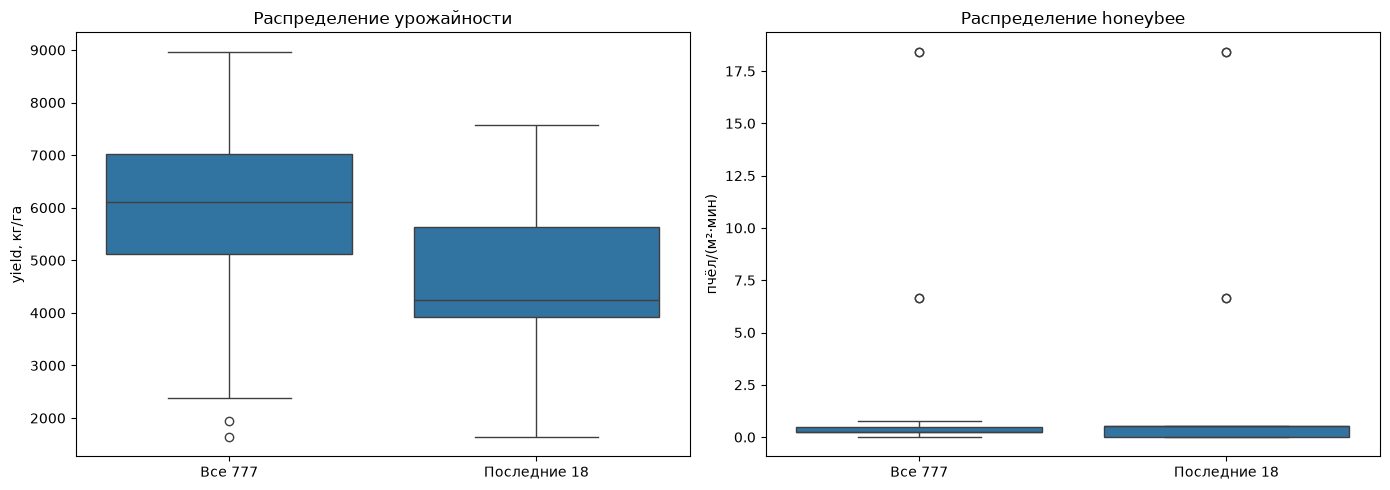

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(
    data=pd.concat([
        df.assign(subsample="Все 777"),
        df_tail18.assign(subsample="Последние 18")
    ]),
    x="subsample", y="yield", ax=axes[0]
)
axes[0].set_title("Распределение урожайности")
axes[0].set_xlabel("")
axes[0].set_ylabel("yield, кг/га")

plot_data = pd.concat([
    df.assign(subsample="Все 777"),
    df_tail18.assign(subsample="Последние 18")
])
sns.boxplot(data=plot_data, x="subsample", y="honeybee", ax=axes[1])
axes[1].set_title("Распределение honeybee")
axes[1].set_xlabel("")
axes[1].set_ylabel("пчёл/(м²·мин)")
plt.tight_layout()
plt.show()

#### **Вывод**
Возможно, эти данные моделируют какие-то особено экстремальные условия, но они добавляют категории почти всем признакам. 
- **Решение:** разделить датасет на еще два, основной и дополнительный, с этим набором данных и отделный только с "особыми" данными.

In [48]:
df_first759.info()

<class 'pandas.DataFrame'>
RangeIndex: 760 entries, 0 to 759
Data columns (total 17 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   clonesize             760 non-null    float64
 1   honeybee              760 non-null    float64
 2   bumbles               760 non-null    float64
 3   andrena               760 non-null    float64
 4   osmia                 760 non-null    float64
 5   MaxOfUpperTRange      760 non-null    float64
 6   MinOfUpperTRange      760 non-null    float64
 7   AverageOfUpperTRange  760 non-null    float64
 8   MaxOfLowerTRange      760 non-null    float64
 9   MinOfLowerTRange      760 non-null    float64
 10  AverageOfLowerTRange  760 non-null    float64
 11  RainingDays           760 non-null    float64
 12  AverageRainingDays    760 non-null    float64
 13  fruitset              760 non-null    float64
 14  fruitmass             760 non-null    float64
 15  seeds                 760 non-null

## 2.5. Распределения и потенциальные выбросы

Сначала смотрим полную выборку. Boxplot показывает необычные значения по формальному правилу, но не даёт права автоматически их удалять.

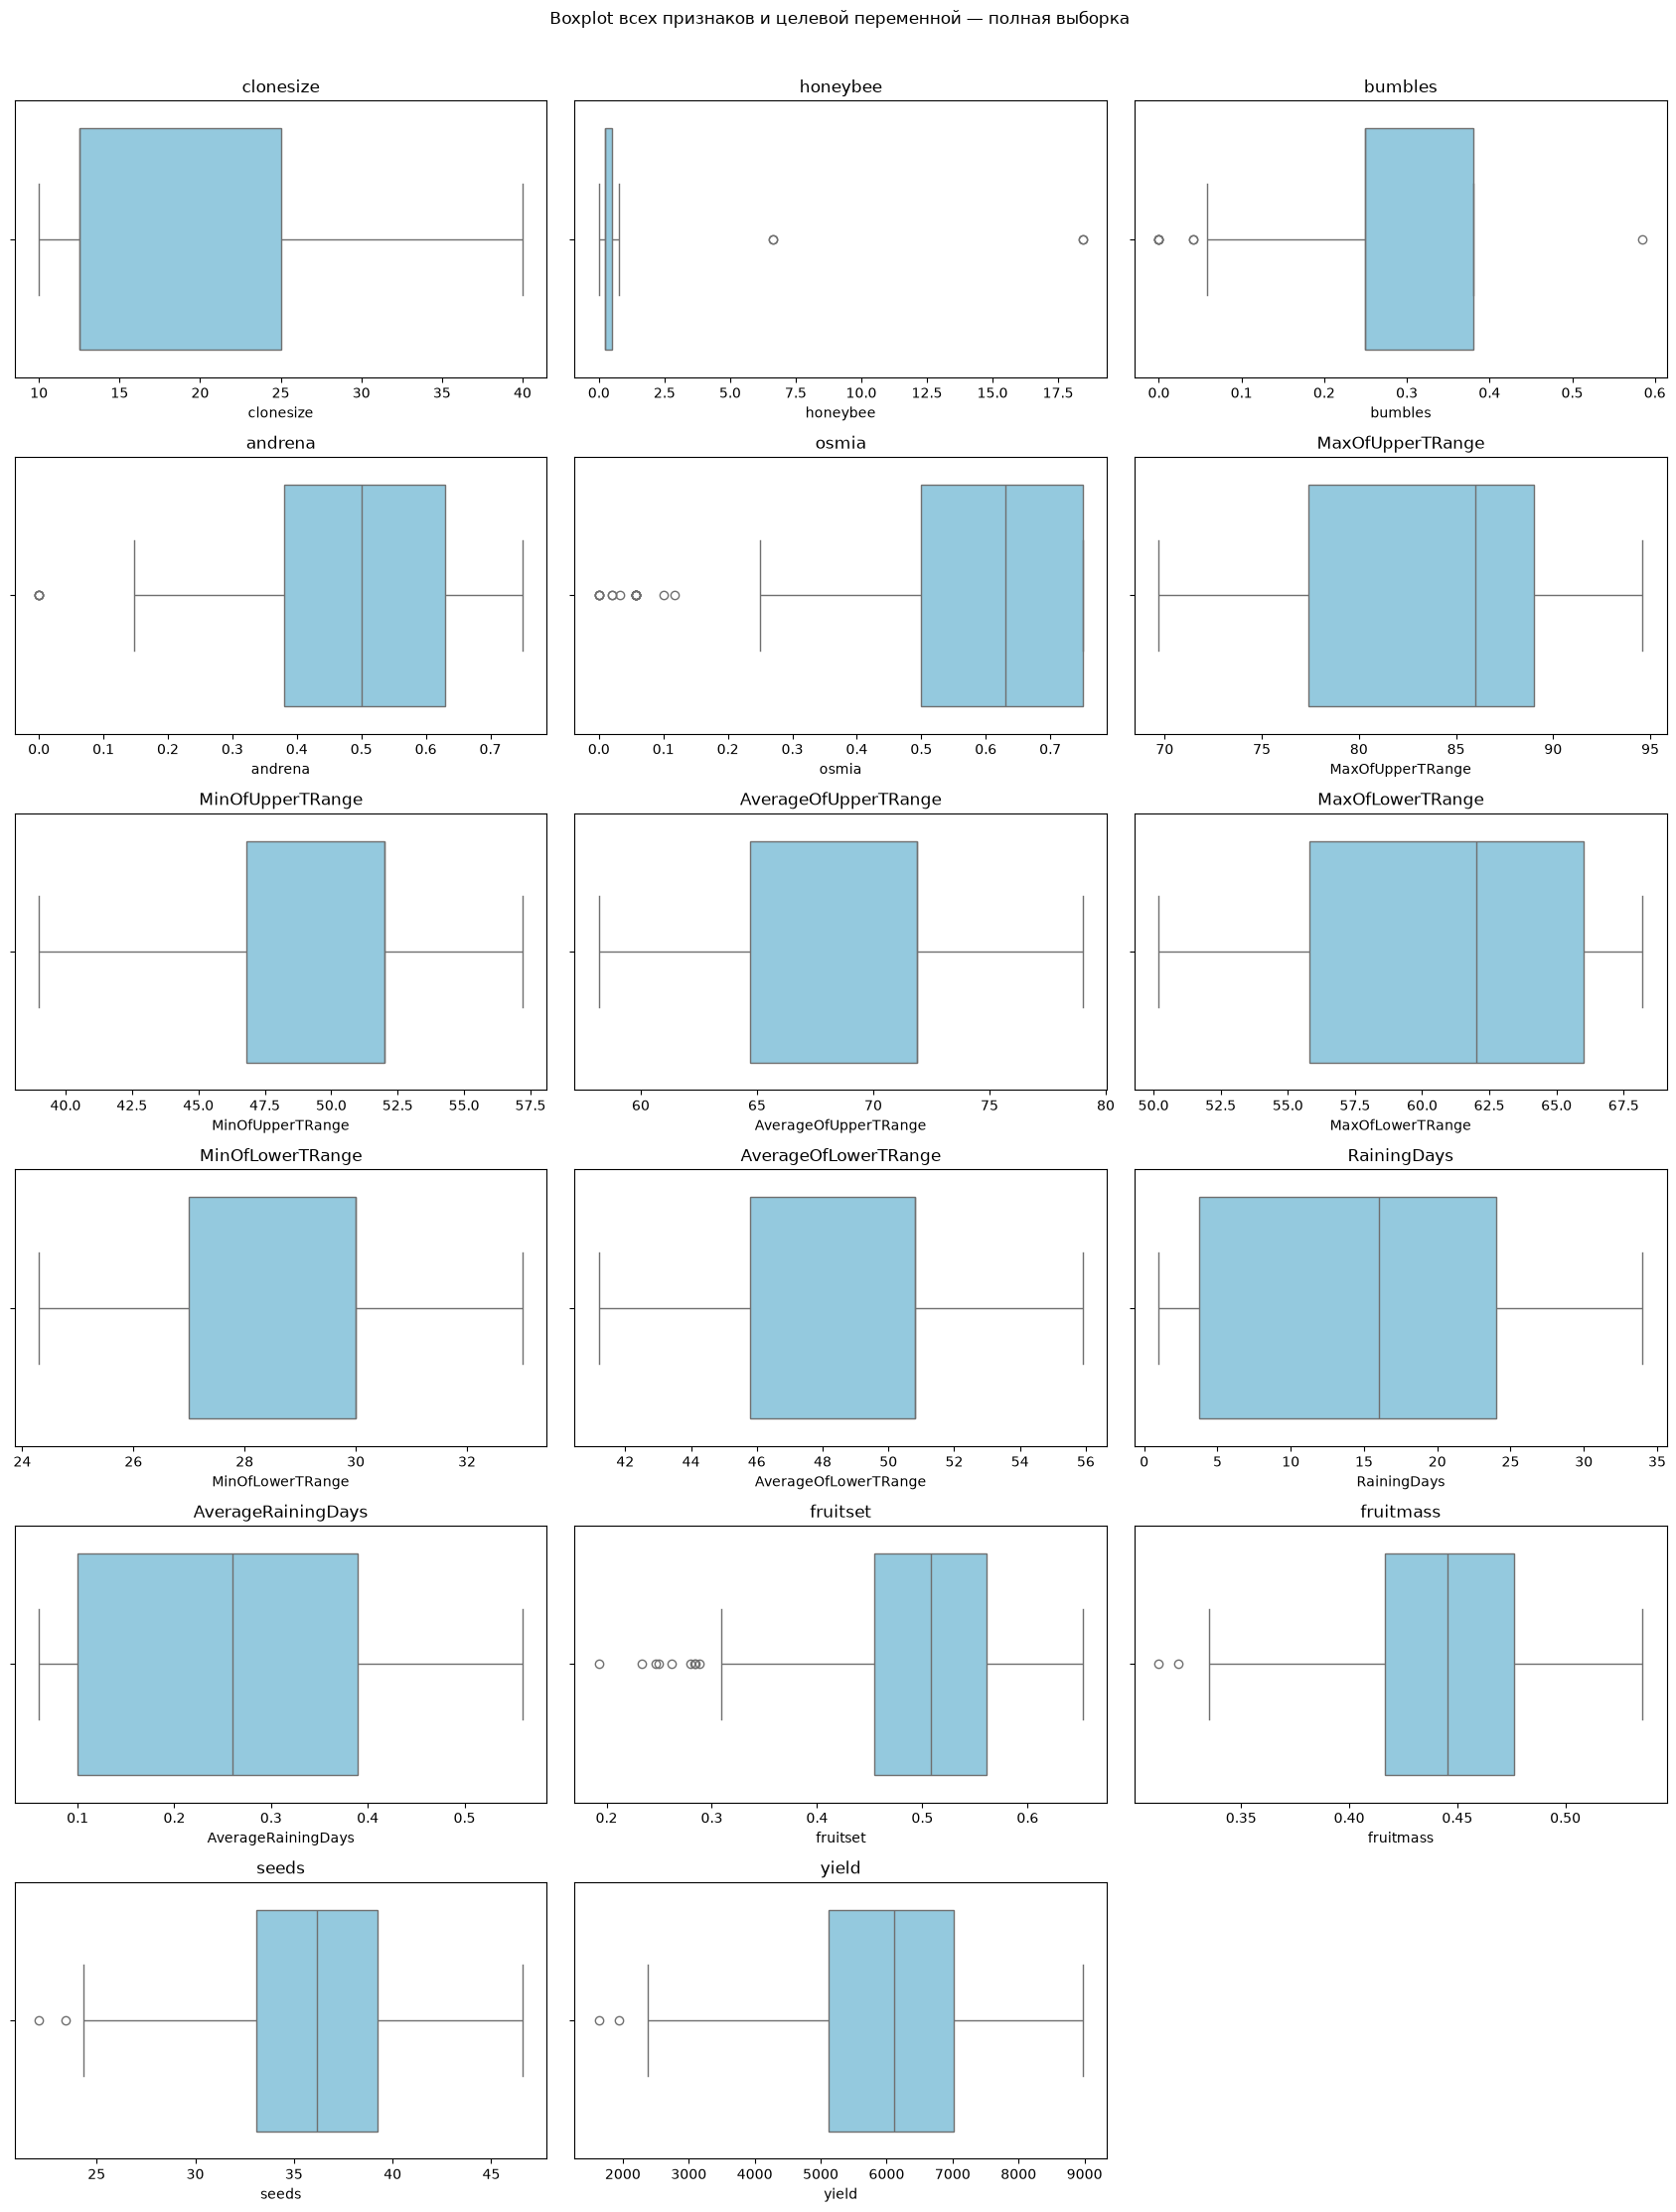

,IQR_low,IQR_high,n_outside_IQR,percent
Признак,,,,
clonesize,-6.250,43.750,0,0.000
honeybee,-0.125,0.875,4,0.515
bumbles,0.055,0.575,7,0.901
andrena,0.005,1.005,4,0.515
osmia,0.125,1.125,17,2.188
MaxOfUpperTRange,60.000,106.400,0,0.000
MinOfUpperTRange,39.000,59.800,0,0.000
AverageOfUpperTRange,53.900,82.700,0,0.000
MaxOfLowerTRange,40.500,81.300,0,0.000


In [ ]:
# Смотрим по оновному датасету
numeric_cols = df.columns.tolist()
fig, axes = plt.subplots(6, 3, figsize=(17, 22))
axes = axes.flatten()
for ax, col in zip(axes, numeric_cols):
    sns.boxplot(x=df[col], ax=ax, color="skyblue")
    ax.set_title(col)
for ax in axes[len(numeric_cols):]:
    ax.set_visible(False)
plt.suptitle("Boxplot всех признаков и целевой переменной — полная выборка", y=1.01)
plt.tight_layout()
plt.show()

# Классические IQR-границы: используем для флага, а не удаления.
outlier_rows = []
for col in numeric_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[col] < low) | (df[col] > high)
    outlier_rows.append({
        "Признак": col,
        "IQR_low": low,
        "IQR_high": high,
        "n_outside_IQR": int(mask.sum()),
        "percent": mask.mean() * 100
    })

iqr_report = pd.DataFrame(outlier_rows).set_index("Признак")
display(iqr_report.round(3))

#### Вывод
- Данные в целом чистые, выбросов мало и не требует удаления, поскольку доля отклонений нигде не превышает 2.2%, жесткая фильтрация по IQR может привести к потере редких, но валидных сценариев. 
- Вместо удаления выбросов, стоит проверить корреляцию между низкими значениями yield и экстермально высокими значениями honeybee.
- Использовать устойчивые к выбросам модели

# Часть 3. Качество данных

## 3.1 Пропуски данных
- пропуски отсутствуют

## 3.2 Поиск дубликатов

In [57]:
# Полные дубликаты
full_duplicates = df.duplicated().sum()
print(f"Полных дубликатов: {full_duplicates:,}")

Полных дубликатов: 0


#### Вывод
- дубликаты отсутсвуют

## 3.3 Проверка на избыточность

In [56]:
print(df.nunique().sort_values())

MinOfUpperTRange          5
AverageOfUpperTRange      5
MaxOfUpperTRange          5
AverageRainingDays        5
RainingDays               5
AverageOfLowerTRange      5
MinOfLowerTRange          5
MaxOfLowerTRange          5
clonesize                 6
honeybee                  7
bumbles                  10
andrena                  12
osmia                    12
fruitset                777
fruitmass               777
seeds                   777
yield                   777
dtype: int64


## 3.4 Проверка распределения целевой переменной (yield)

Сравнение статистик yield:


,Весь датасет,Без последних 18,Последние 18 строк
count,777.00,759.00,18.00
mean,6012.85,6046.21,4606.27
std,1356.96,1338.28,1431.54
min,1637.70,1945.53,1637.70
25%,5124.85,5166.62,3928.71
50%,6107.38,6133.00,4240.39
75%,7022.19,7042.97,5626.95
max,8969.40,8969.40,7575.80


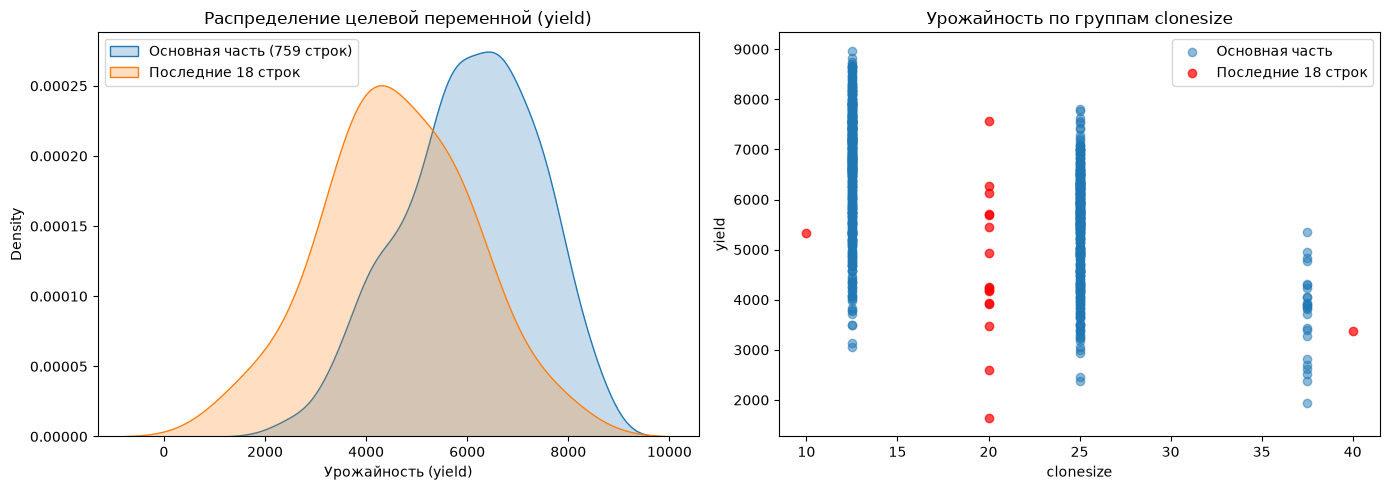

In [64]:
# Количество последних строк, которое вы проверяли
n_tail = 18

# Разделяем данные для сравнения
df_main = df.iloc[:-n_tail]
df_tail = df.iloc[-n_tail:]

# 1. Сравнение статистик целевой переменной (yield)
stats_comparison = pd.DataFrame({
    'Весь датасет': df['yield'].describe(),
    f'Без последних {n_tail}': df_main['yield'].describe(),
    f'Последние {n_tail} строк': df_tail['yield'].describe()
})

print("Сравнение статистик yield:")
display(stats_comparison.round(2))

# 2. Визуализация распределения yield и ключевых признаков
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Распределение урожайности (yield)
sns.kdeplot(df_main['yield'], label=f'Основная часть ({len(df_main)} строк)', ax=axes[0], fill=True)
sns.kdeplot(df_tail['yield'], label=f'Последние {n_tail} строк', ax=axes[0], fill=True)
axes[0].set_title('Распределение целевой переменной (yield)')
axes[0].set_xlabel('Урожайность (yield)')
axes[0].legend()

# График 2: Зависимость урожайности от размера куста (clonesize)
axes[1].scatter(df_main['clonesize'], df_main['yield'], alpha=0.5, label='Основная часть')
axes[1].scatter(df_tail['clonesize'], df_tail['yield'], color='red', alpha=0.7, label=f'Последние {n_tail} строк')
axes[1].set_title('Урожайность по группам clonesize')
axes[1].set_xlabel('clonesize')
axes[1].set_ylabel('yield')
axes[1].legend()

plt.tight_layout()
plt.show()


**Вывод**
- Последние 18 строок, представляют из себя корректные данные из отдельной эсксперементальной группы, смещение статистик объясняется малой выборкой и особенностями этой группы. 
- График плотности распределения сдвинут влево и ниже пиком (урожайность ниже), но лежит внутри границ основного распределения.
- В этой выборке добавлены данные с определенным размером "clonesize".
- При разбиении на train test (или стратификацию по clonesize) эти данные необходимо перемешать с основной выборкой.

## **3.5 Распределение урожая (целевая переменная)**

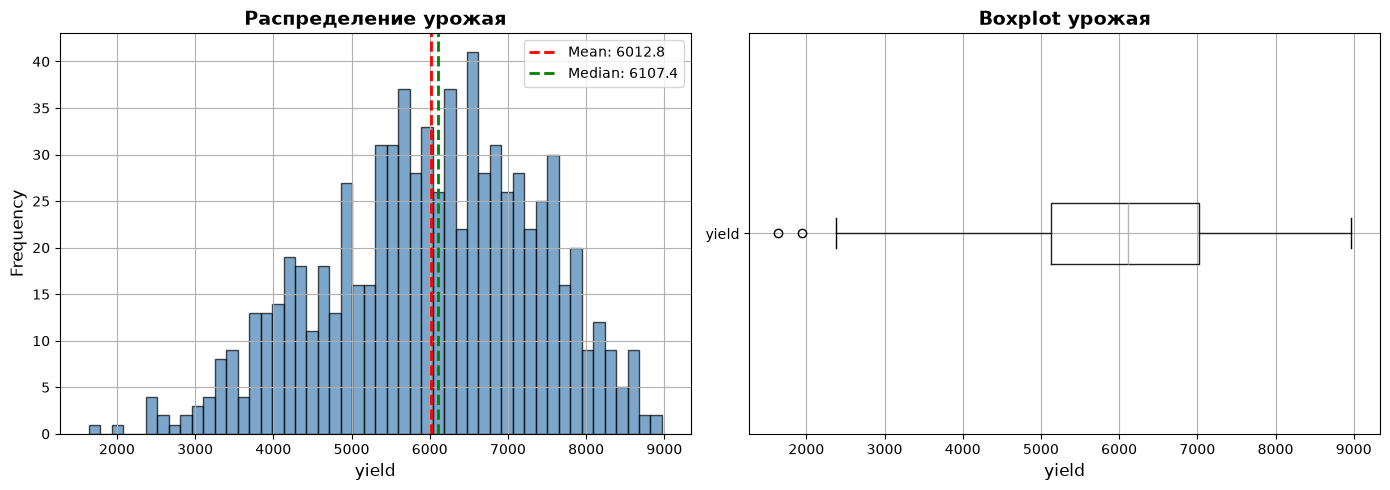

In [63]:
# Распределение урожая
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Гистограмма
ax1 = axes[0]
df['yield'].hist(bins=50, ax=ax1, color='steelblue', edgecolor='black', alpha=0.7)
ax1.axvline(df['yield'].mean(), 
            color='red', linestyle='--', linewidth=2, label=f'Mean: {df["yield"].mean():.1f}')
ax1.axvline(df['yield'].median(), 
            color='green', linestyle='--', linewidth=2, label=f'Median: {df["yield"].median():.1f}')
ax1.set_xlabel('yield', fontsize=12)
ax1.set_ylabel('Frequency', fontsize=12)
ax1.set_title('Распределение урожая', fontsize=14, fontweight='bold')
ax1.legend(fontsize=10)

# KDE + Boxplot
ax2 = axes[1]
df.boxplot(column='yield', ax=ax2, vert=False)
ax2.set_title('Boxplot урожая', fontsize=14, fontweight='bold')
ax2.set_xlabel('yield', fontsize=12)


plt.tight_layout()
plt.show()

**Вывод**
- Распределение близко к нормальному, одномодальное (имеет один вырарженный пик в районе 6000-6500, что говорит об однородности данных).
- Среднее и медиана почти совпадают, основной массив значений сосредоточен примерно в диапазоне 5500–7500 кг/га, в диапазоне от 2000 до 9000. Есть пара выбросов.
- Выраженные низкие значения требуют дополнительного исследования, поскольку могут отражать неблагоприятные условия опыления и цветения.

## 3.6 Распределение природных параметров

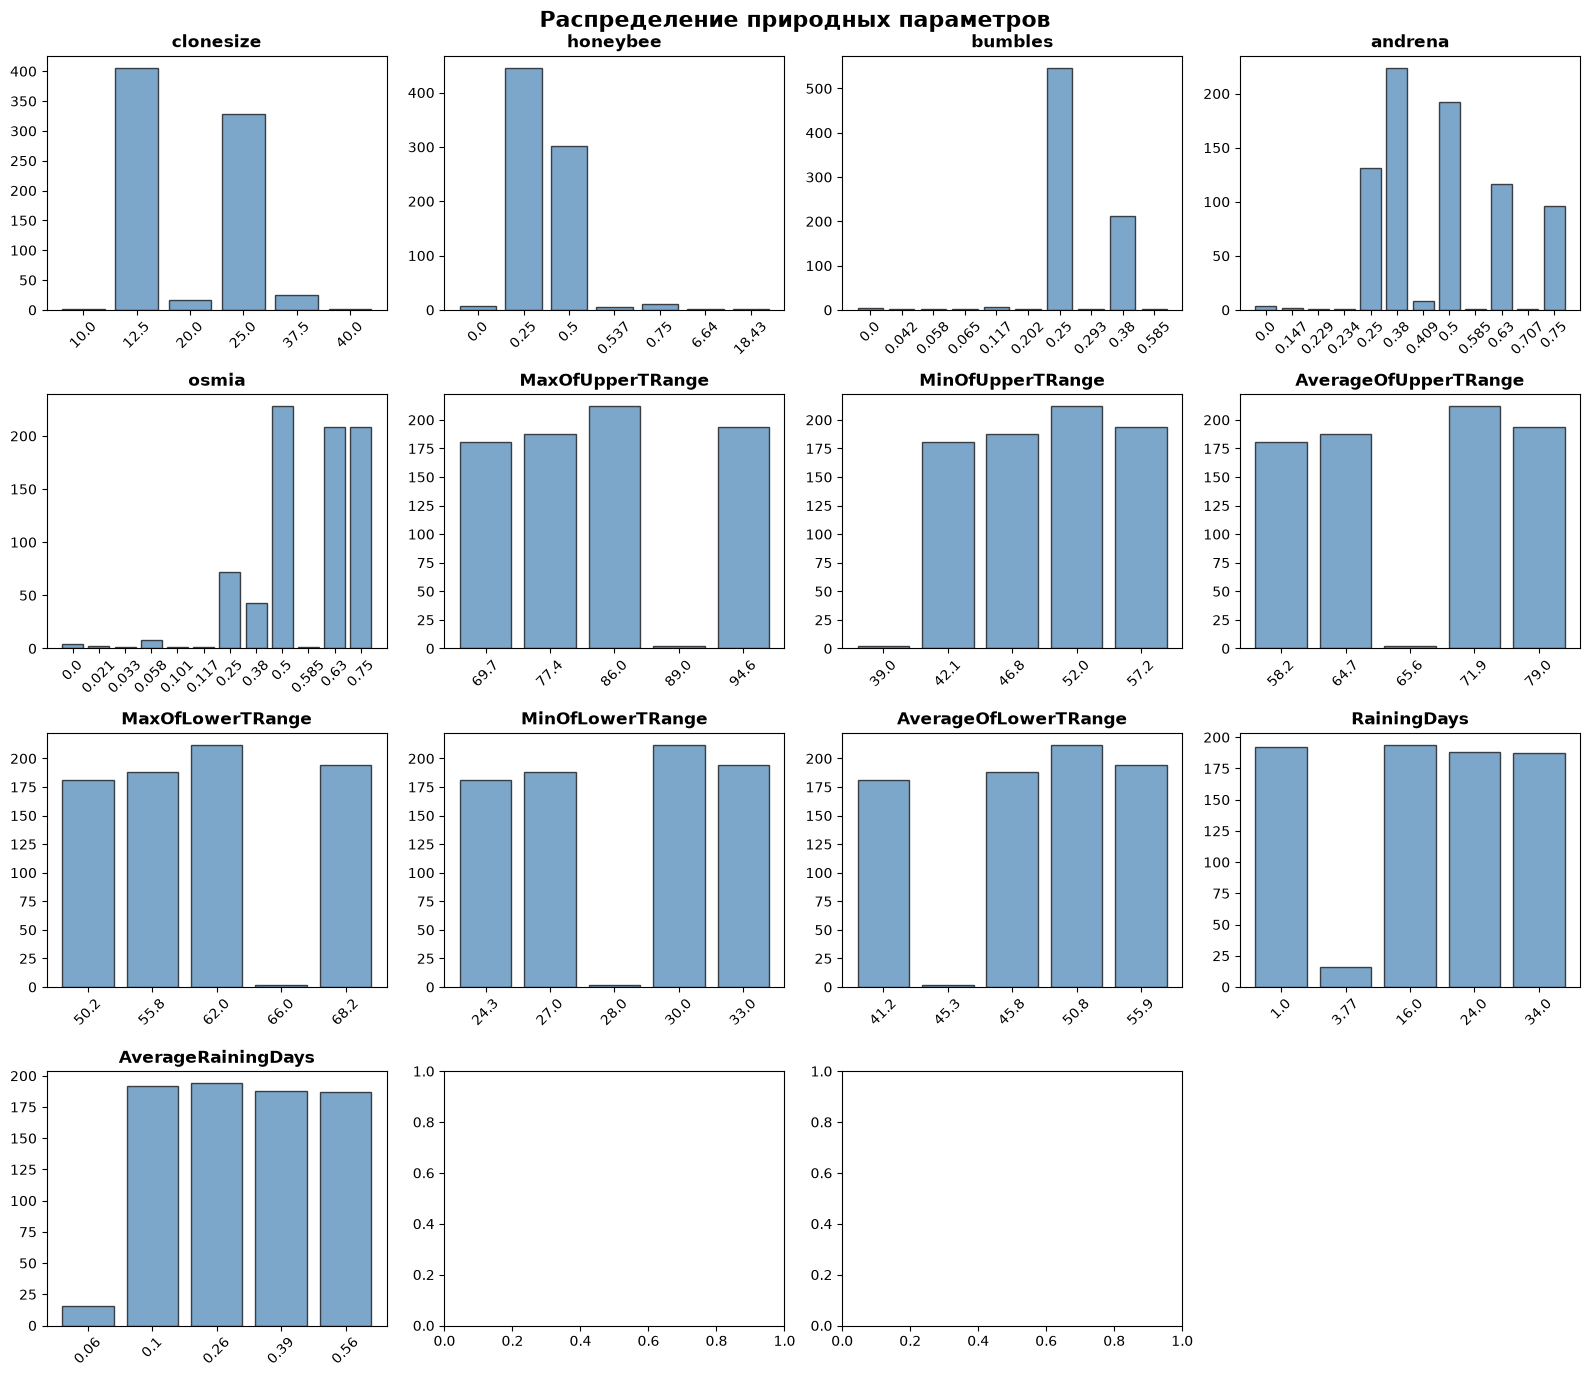

In [73]:
# Параметры дискретные, поэтому вместо гистрограммы столбчатая диаграмма
cols_to_drop = ["fruitset", "fruitmass", "seeds", "yield"]
df_nature = df.drop(columns=cols_to_drop)
fig, axes = plt.subplots(4, 4, figsize=(16, 14))

for ax, col in zip(axes.flatten(), df_nature):
    counts = df[col].value_counts().sort_index()
    ax.bar(counts.index.astype(str), counts.values, color='steelblue', edgecolor='black', alpha=0.7)
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.tick_params(axis='x', rotation=45)
axes.flatten()[-1].set_visible(False)

plt.suptitle('Распределение природных параметров', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

In [80]:
#print(df["honeybee"].value_counts(), df["bumbles"].value_counts())
for col in ["honeybee", "bumbles", "osmia"]:
    display(df[col].value_counts().to_frame(f"Колличество ({col})"))


,Колличество (honeybee)
honeybee,
0.250,446
0.500,302
0.750,11
0.000,8
0.537,6
6.640,2
18.430,2


,Колличество (bumbles)
bumbles,
0.250,547
0.380,212
0.117,7
0.000,4
0.042,2
0.202,1
0.065,1
0.585,1
0.293,1


,Колличество (osmia)
osmia,
0.500,228
0.630,208
0.750,208
0.250,72
0.380,43
0.058,8
0.000,4
0.021,2
0.101,1


**Вывод**
- Во всех группах присутствуют сильно не сбалансированные столбцы значений.
- Распределения признаков неоднородны. Некоторые уровни представлены значительно большим количеством наблюдений, чем другие. Это является особенностью плана симуляционного эксперимента. При построении моделей необходимо учитывать различную представленность экспериментальных сценариев и контролировать устойчивость результатов на редких уровнях факторов.
- При разделении на обучающую и тестовую выборки нужно следить, чтобы редкие сценарии не исчезли из одной из частей.


## 3.7 Распределение данных, формирующих непосредственно урожай

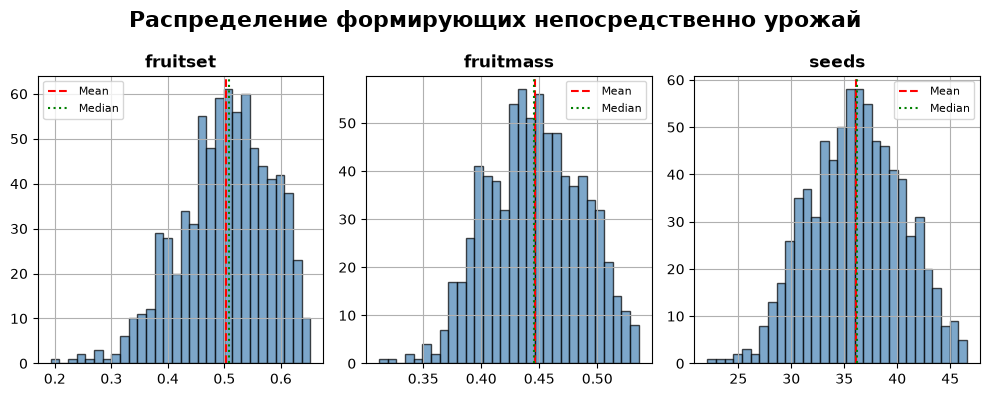

In [74]:
# Параметры дискретные, поэтому вместо гексограмм столбчатая диаграмма
germ = ["fruitset", "fruitmass", "seeds"]
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for ax, col in zip(axes, germ):
    df[col].hist(bins=30, ax=ax, color='steelblue', edgecolor='black', alpha=0.7)
    ax.axvline(df[col].mean(), color='red', linestyle='--', label='Mean')
    ax.axvline(df[col].median(), color='green', linestyle=':', label='Median')
    ax.set_title(col, fontsize=12, fontweight='bold')
    ax.legend(fontsize=8)
plt.suptitle('Распределение формирующих непосредственно урожай', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

**Вывод**
- Распределение близко к нормальному, одномодальное, имеет один вырарженный пик.
- Среднее и медиана почти совпадают.

## 3.8. Первичный графический анализ взаимосвязей (Pairplot)

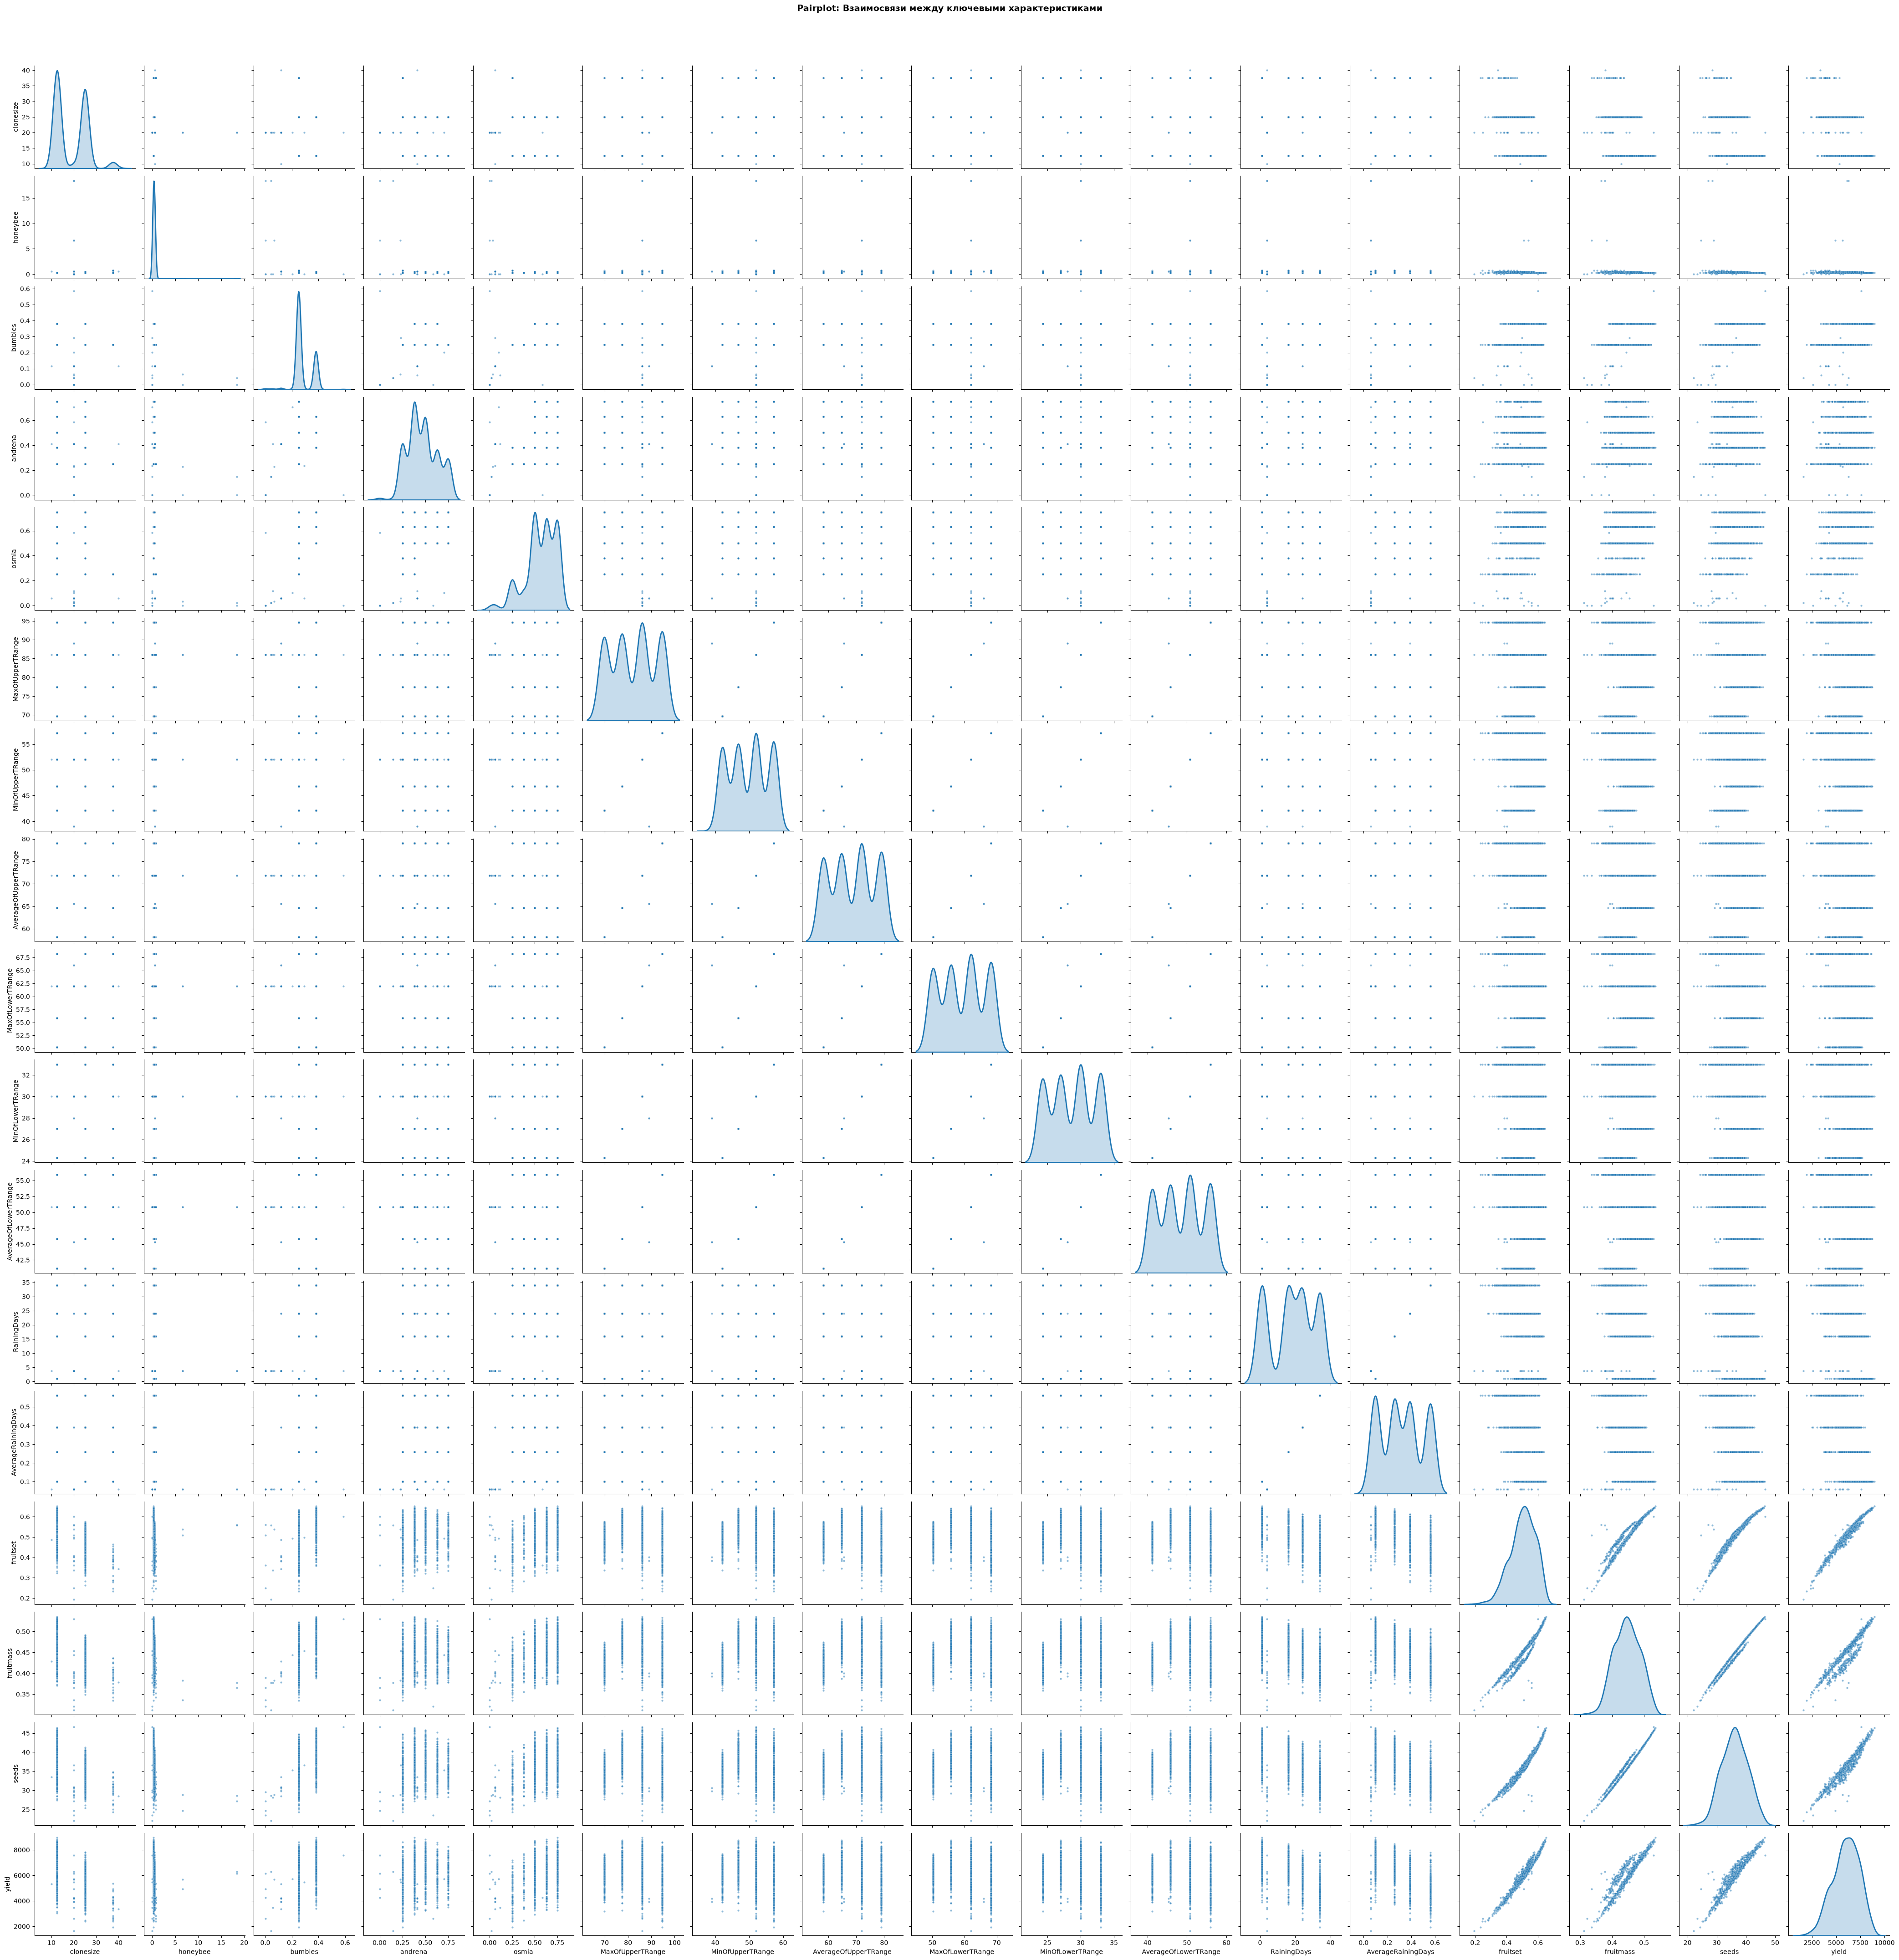

In [81]:
# Pairplot
sns.pairplot(df, diag_kind='kde',
             plot_kws={'alpha': 0.5, 's': 10},
             diag_kws={'linewidth': 2})
plt.suptitle('Pairplot: Взаимосвязи между ключевыми характеристиками',
             fontsize=14, fontweight='bold', y=1.02)
plt.show()

**Вывод**
- "fruitset", "fruitmass", "seeds" демонстируют почти идеальную линейную связь, как с целевой переменной, так и между собой. Это означает, что с увеличением завязываемости плодов обычно растут масса плода, количество семян и итоговая урожайность.
- Погодные условия. Температурные характеристики образуют практически совпадающие линейные зависимости. Два показателя осадков также тесно связаны.
- Внешние факторы: опылтители, размер куста. Здесь заметны связи размера клона с плотностью медоносных пчёл и различия между группами опылителей.

# Часть 4. Корреляционный анализ

## 4.1. Пирсон, Спирмен и Кендалл

- **Пирсон** оценивает силу линейной связи.
- **Спирмен** оценивает монотонную связь между рангами и может выявлять монотонную нелинейность.
- **Кендалл tau-b** оценивает согласованность рангов и учитывает совпадающие значения; это полезно для дискретных факторов с большим количеством одинаковых наблюдений.
- **коэффициент VIF (Variance Inflation Factor).** Корреляция видит только парные связи, а VIF проверяет можно ли предсказать один признак через комбинацию всех остальных. Если VIF > 10, признак избыточен, 1 < VIF < 5 - умеренная связь, VIF ~ 1 признак польностью независим от остальных.**

| Метод | Что измеряет | Когда полезен	|
|---------|----------|-------|
| Пирсон | Линейную зависимость | Когда изменение одного признака связано с примерно линейным изменением другого |
| Cпирмен | Монотонную зависимость по рангам | Когда зависимость может быть нелинейной, но сохраняет направление |
| Кендалл | Согласованность рангов | Когда много одинаковых значений и наблюдения имеют повторяющиеся уровни |

Пирсон измеряет линейную связь. Спирмен и Кендалл оценивают монотонную связь по рангам, поэтому полезны, когда зависимость не вполне линейная или признаки имеют ограниченное число повторяющихся уровней.

Для `kendalltau` используется вариант **tau-b**: он учитывает совпадающие ранги. Это особенно важно для `clonesize`, погодных условий и плотности некоторых опылителей, где много одинаковых значений.

Коэффициент показывает направление и силу связи, но **не доказывает причинное влияние**.

Корреляция не доказывает причинность. Все коэффициенты ниже рассчитываются на полной выборке `df`.

In [107]:
correlation_features = [
    "clonesize", "honeybee", "bumbles", "andrena", "osmia",
    "MaxOfUpperTRange", "MinOfUpperTRange", "AverageOfUpperTRange",
    "MaxOfLowerTRange", "MinOfLowerTRange", "AverageOfLowerTRange",
    "RainingDays", "AverageRainingDays", "fruitset", "fruitmass", "seeds"
]

corr_rows = []
for col in correlation_features:
    pair = df[[col, "yield"]].dropna()
    if pair[col].nunique() < 2 or pair["yield"].nunique() < 2:
        continue
    pr, pp = pearsonr(pair[col], pair["yield"])
    sr, sp = spearmanr(pair[col], pair["yield"])
    kt, kp = kendalltau(pair[col], pair["yield"], variant="b")
    corr_rows.append({
        "Признак": col,
        "n": len(pair),
        "Pearson_r": pr, "Pearson_p": pp,
        "Spearman_rho": sr, "Spearman_p": sp,
        "Kendall_tau_b": kt, "Kendall_p": kp
    })

corr_yield = pd.DataFrame(corr_rows).set_index("Признак")
for p_col, adj_col in [
    ("Pearson_p", "Pearson_p_FDR"),
    ("Spearman_p", "Spearman_p_FDR"),
    ("Kendall_p", "Kendall_p_FDR")
]:
    corr_yield[adj_col] = multipletests(corr_yield[p_col], method="fdr_bh")[1]

display(corr_yield.sort_values("Spearman_rho", key=lambda s: s.abs(), ascending=False).round(4))

,n,Pearson_r,Pearson_p,Spearman_rho,Spearman_p,Kendall_tau_b,Kendall_p,Pearson_p_FDR,Spearman_p_FDR,Kendall_p_FDR
Признак,,,,,,,,,,
fruitset,777,0.9841,0.0000,0.9815,0.0000,0.8925,0.0000,0.0000,0.0000,0.0000
seeds,777,0.9612,0.0000,0.9636,0.0000,0.8476,0.0000,0.0000,0.0000,0.0000
fruitmass,777,0.9304,0.0000,0.9267,0.0000,0.7888,0.0000,0.0000,0.0000,0.0000
RainingDays,777,-0.5401,0.0000,-0.5749,0.0000,-0.4437,0.0000,0.0000,0.0000,0.0000
AverageRainingDays,777,-0.5412,0.0000,-0.5457,0.0000,-0.4244,0.0000,0.0000,0.0000,0.0000
clonesize,777,-0.5167,0.0000,-0.4978,0.0000,-0.4024,0.0000,0.0000,0.0000,0.0000
honeybee,777,-0.0442,0.2179,-0.3413,0.0000,-0.2801,0.0000,0.2179,0.0000,0.0000
osmia,777,0.3809,0.0000,0.3148,0.0000,0.2372,0.0000,0.0000,0.0000,0.0000
bumbles,777,0.3094,0.0000,0.2861,0.0000,0.2326,0.0000,0.0000,0.0000,0.0000


**Вывод**
- Показатели формирования плодов имеют почти функциональную положительную связь с yield: fruitset (r = 0.9841, rho = 0.9815), seeds (r = 0.9612, rho = 0.9636) и fruitmass (r = 0.9304, rho = 0.9267).
- Нелинейная скрытая связь у honeybee: По линейному коэффициенту Пирсона связь медоносных пчёл с урожайностью близка к нулю и незначима (r = -0.0442, p_FDR = 0.2179). Однако ранговые корреляции Спирмена (rho = -0.3413) и Кендалла (tau = -0.2801) показывают статистически значимую (p_FDR = 0.0000) умеренную обратную связь. Это говорит о сильной нелинейности или влиянии выбросов/дискретных уровней у honeybee.
- Умеренные факторы: Дождливые дни (RainingDays: r = -0.5401) и размер куста (clonesize: r = -0.5167) статистически значимо снижают урожайность, а дикие пчёлы (osmia: r = 0.3809, bumbles: r = 0.3094) умеренно её повышают.


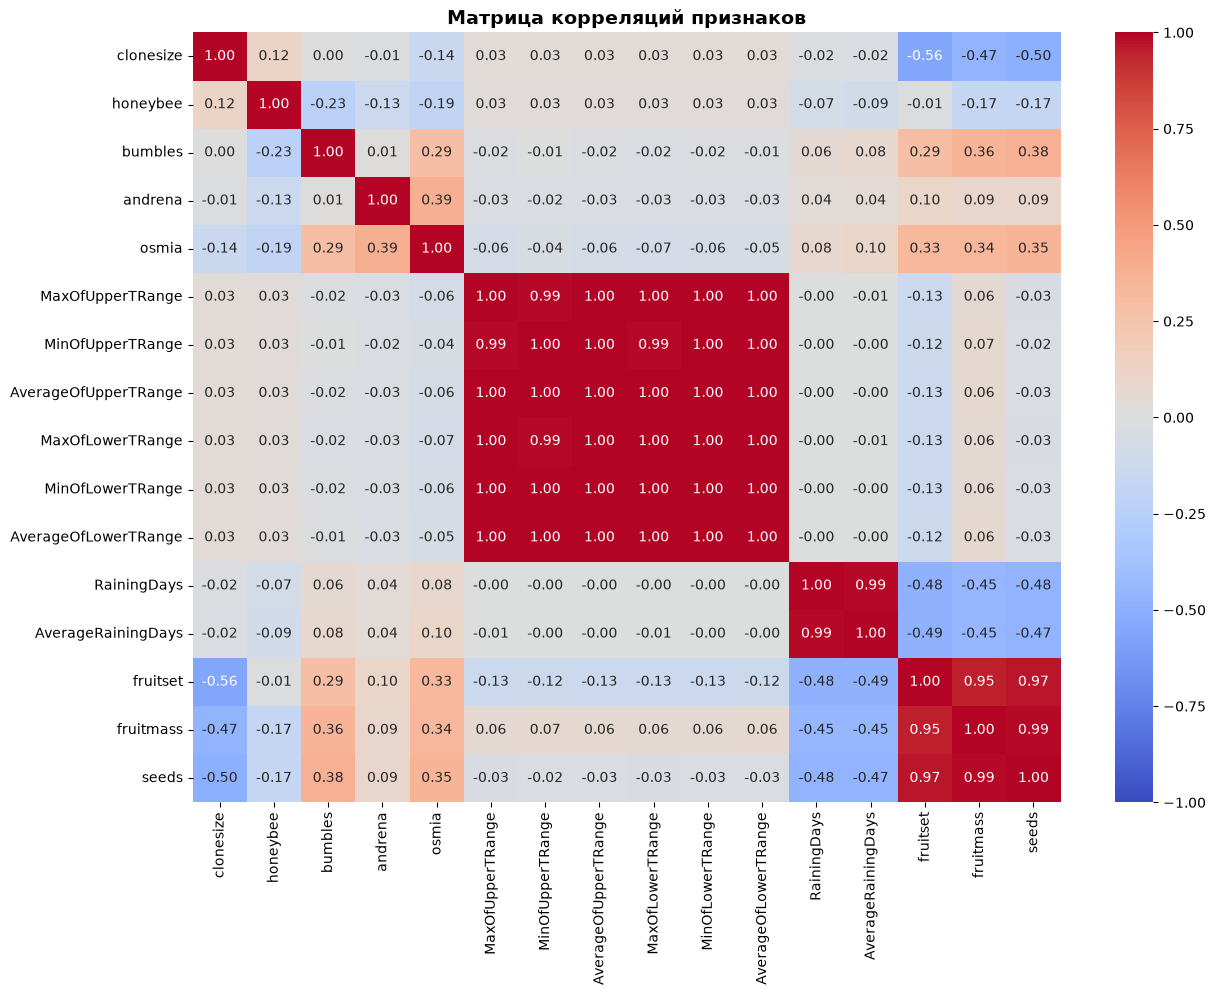

In [108]:
# Считаем матрицу корреляций Пирсона (убираем целевую переменную yield, чтобы сравнивать только признаки)
features = df.drop(columns=['yield'])
corr_matrix = features.corr()

# Строим тепловую карту
plt.figure(figsize=(14, 10))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Матрица корреляций признаков", fontsize=14, fontweight='bold')
plt.show()

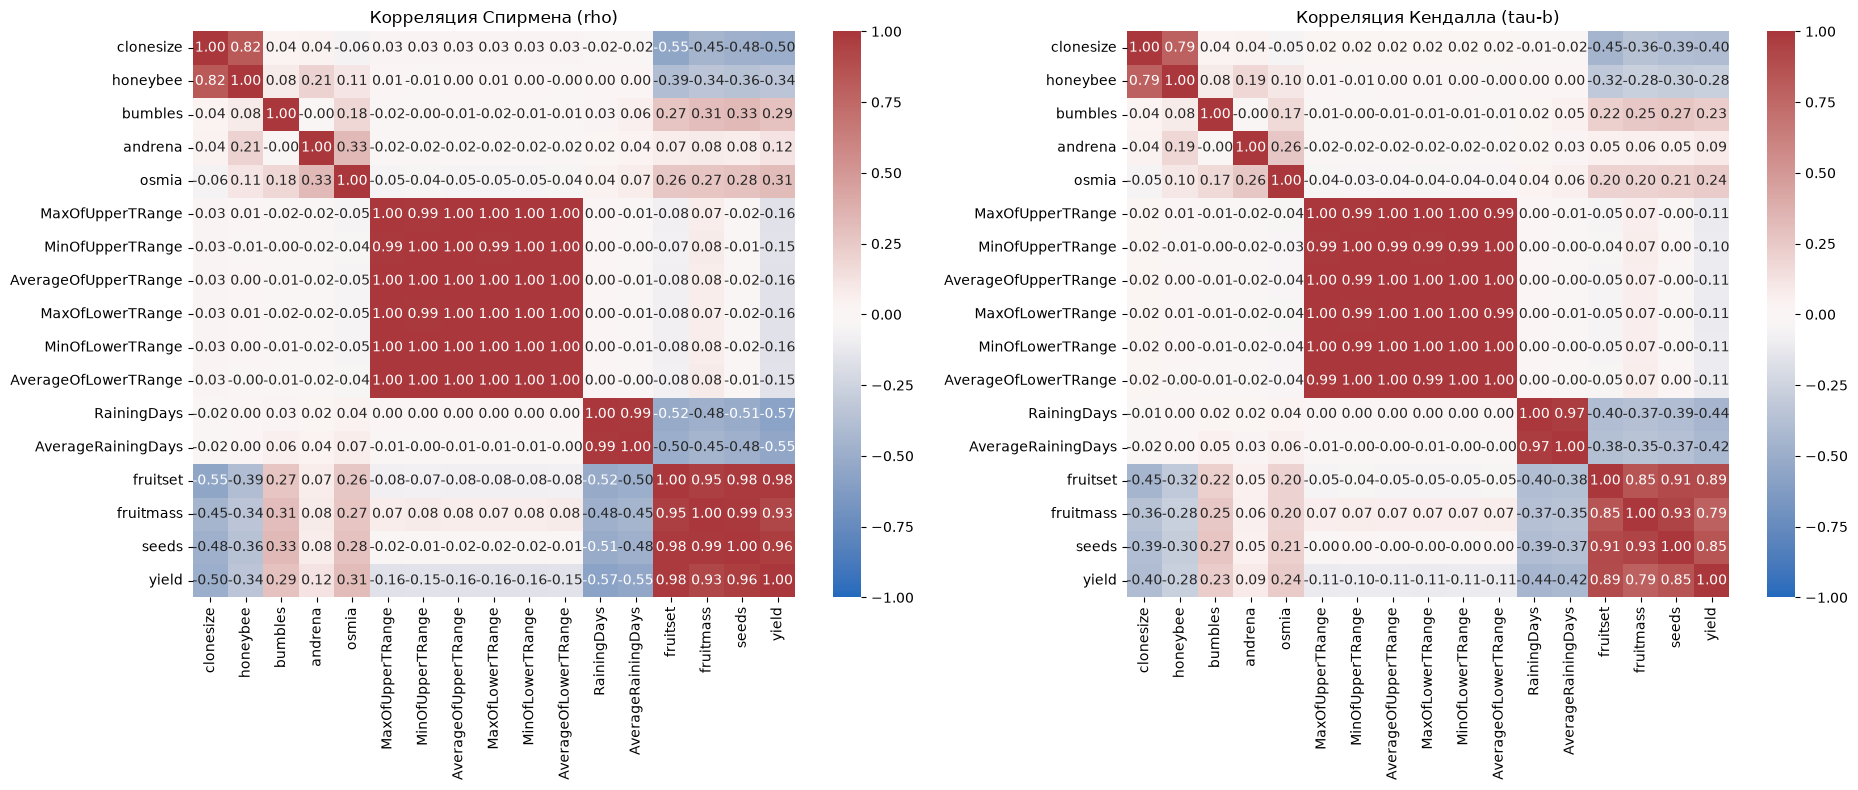

In [109]:
# Полная выборка — все 777 записей

# Матрицы ранговых корреляций
spearman_matrix = df.corr(method="spearman")
kendall_matrix = df.corr(method="kendall")

fig, axes = plt.subplots(1, 2, figsize=(19, 8))
sns.heatmap(spearman_matrix, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Корреляция Спирмена (rho)")
sns.heatmap(kendall_matrix, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, ax=axes[1])
axes[1].set_title("Корреляция Кендалла (tau-b)")
plt.tight_layout()
plt.show()

**Вывод**
- Три жёстких блока дубликатов (красные квадраты со значениями 0.99 – 1.00):
	1. Все 6 температурных признаков (Max/Min/Average для UpperTRange и LowerTRange) коррелируют друг с другом на уровне 0.99 – 1.00.
	2. Показатели осадков RainingDays и AverageRainingDays имеют корреляцию 0.99.
	3. Характеристики плодов fruitset, fruitmass и seeds связаны между собой на уровне 0.95 – 0.99.
- Скрытая связь между clonesize и honeybee: На матрице Пирсона их связь выглядит слабой (0.12), но по Спирмену (0.82) и Кендаллу (0.79) она оказывается очень сильной. Возможно, в эксперименте плотность ульев honeybee задавалась почти пропорционально размеру куста clonesize, но нелинейно (ступенчато).


In [10]:
# Проверка по VIF
from statsmodels.stats.outliers_influence import variance_inflation_factor

# Создаем таблицу Х, только с входными признаками
X = df.drop(columns=['yield'])

# Создаем пустую таблицу, куда будем записывать результаты
vif_data = pd.DataFrame()

# Создаем столбец и заполняем его
vif_data["Признак"] = X.columns
vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]

# Сортируем от самых избыточных к независимым
print(vif_data.sort_values(by="VIF", ascending=False))

                 Признак           VIF
6       MinOfUpperTRange  1.000800e+15
7   AverageOfUpperTRange  1.000800e+15
5       MaxOfUpperTRange  1.000800e+15
8       MaxOfLowerTRange  1.000800e+15
9       MinOfLowerTRange  1.000800e+15
10  AverageOfLowerTRange  1.000800e+15
14             fruitmass  7.643746e+02
15                 seeds  5.667084e+02
13              fruitset  8.087148e+01
12    AverageRainingDays  7.131775e+01
11           RainingDays  6.410320e+01
0              clonesize  3.800417e+00
1               honeybee  3.479346e+00
2                bumbles  2.232211e+00
4                  osmia  1.885464e+00
3                andrena  1.277828e+00


C:\Users\denis\AppData\Local\Temp\ipykernel_11740\2064229799.py:12: UserWarning: The design matrix is poorly conditioned (condition number=1.39e+16). VIF calculations may be numerically unstable.
  vif_data["VIF"] = [variance_inflation_factor(X.values, i) for i in range(X.shape[1])]
c:\МАГИСТРАТУРА\Проектный практикум\project\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\МАГИСТРАТУРА\Проектный практикум\project\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  r_sq = OLS(x_i, x_noti).fit().rsquared
c:\МАГИСТРАТУРА\Проектный практикум\project\.venv\Lib\site-packages\statsmodels\stats\outliers_influence.py:235: SingularMatrixWarning: The design matrix is rank-deficient. The model param

**Вывод**
- Абсолютная линейная зависимость (VIF ≈ 1.00 × 10^15): Все 6 температурных признаков имеют практически бесконечный VIF (число с 15 нулями). Это означает, что столбцы связаны точной математической формулой (например, среднее вычислено из минимума и максимума), из-за чего матрица признаков вырождена.
- Критическая мультиколлинеарность (VIF > 50):
	1. Характеристики плодов: fruitmass (764.37), seeds (566.71), fruitset (80.87).
	2. Осадки: AverageRainingDays (73.14), RainingDays (64.10).
- Независимые признаки (VIF < 5): Только clonesize (3.80), honeybee (3.48), bumbles (2.23), osmia (1.89) и andrena (1.28) не дублируют другие столбцы линейно.


### **Общий вывод по анализу корреляций**

1. Данные сильно избыточны: Из 16 входных признаков реальную уникальную информацию несут только около 7–8 признаков. Остальные являются либо линейными комбинациями (температуры), либо тесно связанными биологическими следствиями одного процесса (завязываемость плодов → количество семян → масса плода → урожайность).
2. Присутствует важная нелинейность: Расхождение между Пирсоном и Спирменом/Кендаллом для honeybee и clonesize доказывает, что зависимости в датасете носят нелинейный или пороговый характер.
3. Риск утечки смысла: Признаки fruitset, seeds и fruitmass измеряются уже на этапе созревания урожая (почти одновременно с yield), поэтому они объясняют более 95% дисперсии таргета, полностью «забивая» погодные факторы и работу пчёл.

Что можно сделать:
- Отбор признаков для линейных моделей (Linear, Ridge, Lasso). Оставить по 1 представителю из каждого кластера дублей: например, только AverageOfUpperTRange (из 6 температур), AverageRainingDays (из 2 осадков) и fruitset (из 3 характеристик плода).	При VIF = 10^15 обычная линейная регрессия математически нестабильна (деление на числа, близкие к нулю), а веса признаков потеряют физический смысл.

Решение:

| **Данные** | **Описание** | **Оставляем:** |
|---------|----------|-------|
| **'MaxOfUpperTRange'**, **'MinOfUpperTRange'**, **'AverageOfUpperTRange'**, **'MaxOfLowerTRange'**,**'MinOfLowerTRange'**, **'AverageOfLowerTRange'** | Все шесть температурных признака обладают абсолютной избыточностью (VIF показал, что все температурные показатели связаны математичекской формулой. | Оставить только одно значение темпертуры, например, **"AverageOfUpperTRange"** |
| **"fruitmass"**, **"fruitset"**, **"seeds"** | Высокая избыточность. Колличество семян, масса ягоды и завязываемость плода зависят друг от друга, больше завязей и семян - больше масса. |  только **"fruitset"**. |
| **"RainingDays"**, **"AverageRainingDays"** | Сильная избыточность. Оба столбца описывают одно и тоже явление. | только "AverageRainingDays" |
| **Виды шмелей** и **пчел** | У видом пчел и шмелей - признаки независимые. | Все столбцы остаются. |

## 4.2 Проверка влияния последних 18 строк

In [18]:
# Переменные, доступные для условного прогноза до появления показателей плодов
early_features = [
    "clonesize", "honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays"
]
# Указываем целевую переменную (если константа TARGET не задана выше, подставьте 'yield')
target_col = 'yield'

# Считаем корреляции Спирмена и Кендалла напрямую через pandas
spearman_full = df[early_features].corrwith(df[target_col], method='spearman')
spearman_no_tail = df_first759[early_features].corrwith(df_first759[target_col], method='spearman')

kendall_full = df[early_features].corrwith(df[target_col], method='kendall')
kendall_no_tail = df_first759[early_features].corrwith(df_first759[target_col], method='kendall')

# Собираем итоговую таблицу сравнения
comparison = pd.DataFrame({
    "Spearman_all_777": spearman_full,
    "Spearman_without_18": spearman_no_tail,
    "Kendall_all_777": kendall_full,
    "Kendall_without_18": kendall_no_tail
})

comparison["Изменение_Spearman"] = (
    comparison["Spearman_without_18"] - comparison["Spearman_all_777"]
)

# Сортируем по модулю корреляции на полном датасете (как делала исходная функция)
comparison = comparison.sort_values("Spearman_all_777", key=lambda s: s.abs(), ascending=False)

display(comparison.round(4))

,Spearman_all_777,Spearman_without_18,Kendall_all_777,Kendall_without_18,Изменение_Spearman
AverageRainingDays,-0.5457,-0.5997,-0.4244,-0.4662,-0.0539
clonesize,-0.4978,-0.5050,-0.4024,-0.4140,-0.0072
honeybee,-0.3413,-0.3561,-0.2801,-0.2924,-0.0149
osmia,0.3148,0.2967,0.2372,0.2245,-0.0181
bumbles,0.2861,0.2559,0.2326,0.2091,-0.0302
AverageOfUpperTRange,-0.1577,-0.1493,-0.1092,-0.1027,0.0084
andrena,0.1232,0.1192,0.0885,0.0860,-0.0041


**Вывод**
- Исключение 18 строк почти не меняет картину: Разница коэффициентов до и после удаления минимальна и составляет от 0.004 до 0.033 почти по всем признакам.
- Умеренный сдвиг только у осадков: Сильнее всего реагирует AverageRainingDays (корреляция Спирмена усиливается с -0.5457 до -0.6053, изменение -0.0596), но направление и сила связи остаются прежними.
- Итог для работы: Удалять последние 18 строк не нужно, так как они не искажают зависимости между признаками и урожайностью.


In [19]:
# 1. Список избыточных столбцов (оставляем по одному из каждой группы)
cols_to_drop = [
    'MinOfUpperTRange', 'MaxOfUpperTRange',
    'MinOfLowerTRange', 'MaxOfLowerTRange', 'AverageOfLowerTRange',
    'RainingDays', 'fruitmass', 'seeds'
]

# Если в таблице остался служебный столбец 'Row#', его тоже лучше убрать:
if 'Row#' in df.columns:
    cols_to_drop.append('Row#')

# 2. Создаем финальный датафрейм без лишних столбцов
df_base = df.drop(columns=cols_to_drop)

# 3. Проверяем VIF на оставшихся признаках (с добавлением константы)
X_check = sm.add_constant(df_base.drop(columns=['yield']))
vif_final = pd.DataFrame({
    'Признак': X_check.columns[1:],
    'VIF': [variance_inflation_factor(X_check.values, i + 1) for i in range(X_check.shape[1] - 1)]
})

print("Оставшиеся столбцы:", list(df_base.columns))
print("\nИтоговая таблица VIF:")
print(vif_final.sort_values(by='VIF', ascending=False).to_string(index=False))

Оставшиеся столбцы: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'fruitset', 'yield']

Итоговая таблица VIF:
             Признак      VIF
            fruitset 3.946684
           clonesize 2.236542
  AverageRainingDays 2.163682
               osmia 1.561095
             bumbles 1.502577
             andrena 1.213441
            honeybee 1.164989
AverageOfUpperTRange 1.038585


In [123]:
# Создаем датафрейм для поиска условий влияния на урожайность
cols_to_drop = ['fruitset']
df_fetus = df_base.drop(columns=cols_to_drop)
print("Оставшиеся столбцы:", list(df_fetus.columns))

Оставшиеся столбцы: ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'yield']


## Итог
Умеренная корреляция осталась у 'clonesize', 'honeybee', 'fruitset'. 
- df - оригинальный датафрейм с добавдением строк другого моделирования или экстеримальных условий.
- df_759 - датафрейм с удалением послдених 18 строк.
- df_base - для прогноза урожайности по основным параметрам.
- df_fetus - для прогноза массы урожая.

---

# **Часть 5. Многомерный анализ**

## **5.2 Корреляционный анализ с φk (phik)**

### **Матрица корреляций φk**

Важно: для корректного расчёта φk нужно явно указать интервальные (непрерывные) переменные через параметр interval_cols. Это позволяет библиотеке правильно определить типы переменных и выбрать соответствующий метод расчёта корреляции.

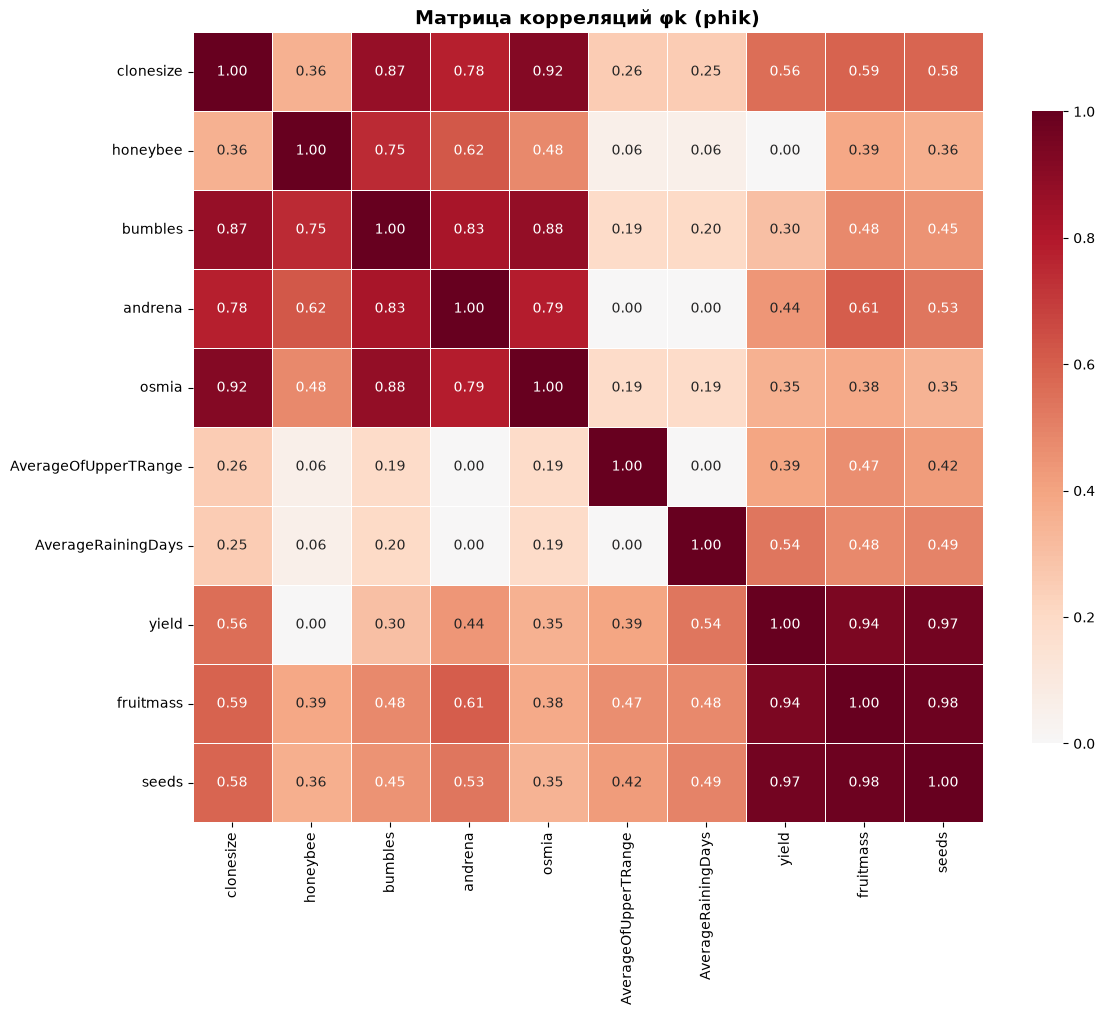

In [134]:
# Определяем интервальные (непрерывные) переменные
interval_cols = ['clonesize', 'honeybee', 'bumbles', 'andrena', 'osmia', 'AverageOfUpperTRange', 'AverageRainingDays', 'yield', "fruitmass", "seeds"]


# Расчёт матрицы phik с явным указанием интервальных переменных
phik_matrix = df[interval_cols].phik_matrix(interval_cols=interval_cols)

# Heatmap
fig, ax = plt.subplots(figsize=(12, 10))
sns.heatmap(phik_matrix, annot=True, fmt='.2f', cmap='RdBu_r', center=0,
            square=True, linewidths=0.5, ax=ax, cbar_kws={'shrink': 0.8})
ax.set_title('Матрица корреляций φk (phik)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


**Вывод**
- В левом верхнем углу образовался яркий красный кластер между размером куста (clonesize) и дикими пчёлами: osmia (0.92), bumbles (0.87), andrena (0.78), а также между самими видами диких пчёл (0.79 – 0.88). У медоносной пчелы (honeybee) связь с bumbles составляет 0.75, с andrena — 0.62.На матрице Пирсона эти корреляции выглядели слабыми (0.00 – 0.39). Высокий phi_k доказывает, что в эксперименте плотность опылителей не менялась случайно, а задавалась жёсткими дискретными комбинациями (сеткой эксперимента) под каждый размер куста clonesize.
- Связь признаков с целевой переменной (yield). 
    1. Почти функциональная зависимость от характеристик плода: Самые высокие значения phi_k с урожайностью имеют seeds (0.97) и fruitmass (0.94), при этом они же на 0.98 связаны между собой.
    2. Умеренное влияние ранних факторов (погоды и среды): clonesize — 0.56, AverageRainingDays — 0.54, andrena — 0.44, osmia — 0.35, bumbles — 0.30,AverageOfUpperTRange — 0.39.
    3. Нулевая связь у honeybee с yield (0.00): В отличие от ранговой корреляции Спирмена (-0.34), метод phi_k оценивает общую связь honeybee и yield как нулевую (0.00). Это подтверждает, что медоносные пчёлы в данном эксперименте не оказывают самостоятельного устойчивого влияния на урожайность (основную работу делают дикие пчёлы andrena, osmia и bumbles).
**Итог**
- Проблема мультиколлинеарности успешно решена для температур и осадков: После удаления дублей (Max/Min TRange и RainingDays) на карте больше нет искусственных единиц (1.00) вне главной диагонали.





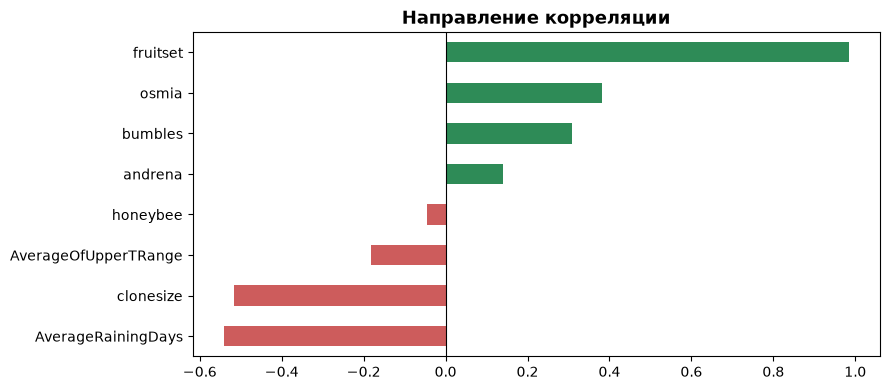

AverageRainingDays     -0.541
clonesize              -0.517
AverageOfUpperTRange   -0.182
honeybee               -0.044
andrena                 0.140
bumbles                 0.309
osmia                   0.381
fruitset                0.984
Name: yield, dtype: float64

In [20]:
pearson = df_base.corr()['yield'].drop('yield').sort_values()

fig, ax = plt.subplots(figsize=(9, 4))
pearson.plot(kind='barh', ax=ax, color=['indianred' if v < 0 else 'seagreen' for v in pearson])
ax.axvline(0, color='black', linewidth=0.8)
ax.set_title('Направление корреляции', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

pearson.round(3)

**Вывод**
- Наибольшее влияние среди внешних факторов оказывают доля дождливых дней и размер клона.
- дикие опылители положительно влияют на урожай, лидирует osmia.
- Отрицательная корреляция honeybee c урожаем объясняется жесткой связью между "honeybee" и "clonesize" в плане эксперимента.  "honeybee" и "clonesize" корреляция 0,97, это значит, что в плане эксперимента плотность медоносных пчел менялась не независимо, а пропроционально размеру куста. Надо проверить.
    

Таблица сопряженности (количество наблюдений):
honeybee   0.000   0.250   0.500   0.537   0.750   6.640   18.430
clonesize                                                        
10.0            0       0       0       1       0       0       0
12.5            0     406       0       0       0       0       0
20.0            8       0       0       4       0       2       2
25.0            0      26     302       0       0       0       0
37.5            0      14       0       0      11       0       0
40.0            0       0       0       1       0       0       0


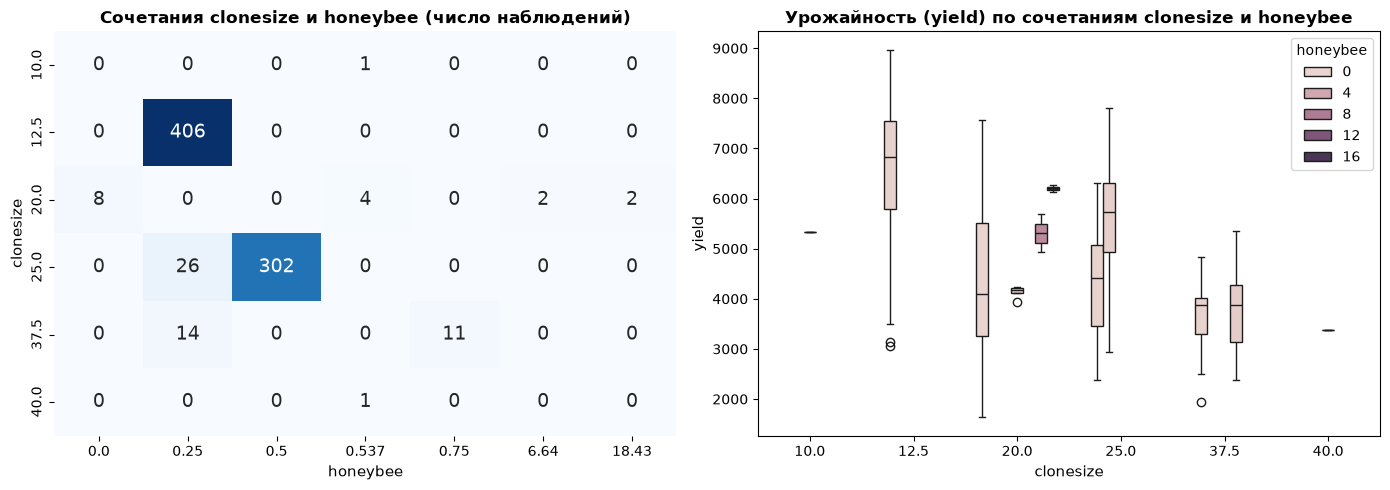

In [24]:
# 1. Таблица сопряженности (сколько наблюдений попадает в каждую пару значений)
ct = pd.crosstab(df_base['clonesize'], df_base['honeybee'])
print("Таблица сопряженности (количество наблюдений):")
print(ct)

# 2. Визуализация в виде тепловой карты и сравнение урожайности по парам
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# График 1: Тепловая карта частот
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False, annot_kws={"size": 14})
axes[0].set_title('Сочетания clonesize и honeybee (число наблюдений)', fontsize=12, fontweight='bold')
axes[0].set_xlabel('honeybee', fontsize=11)
axes[0].set_ylabel('clonesize', fontsize=11)

# График 2: Распределение урожая (yield) внутри каждого сочетания
sns.boxplot(data=df_base, x='clonesize', y='yield', hue='honeybee', ax=axes[1])
axes[1].set_title('Урожайность (yield) по сочетаниям clonesize и honeybee', fontsize=12, fontweight='bold')
axes[1].set_xlabel('clonesize', fontsize=11)
axes[1].set_ylabel('yield', fontsize=11)
axes[1].legend(title='honeybee')

plt.tight_layout()
plt.show()

**Вывод**

Эти графики наглядно объясняют все противоречия между корреляциями Пирсона, Спирмена и phi_k.

1. Признак honeybee почти не даёт прироста качества: Медоносные пчёлы не являются самостоятельным фактором роста урожая — их значение в 91% 
случаев просто дублирует clonesize, а экстремальные выбросы (6.64 и 18.43) не приводят к росту ягод.
2. Если вы будете обучать линейную регрессию или нейросеть, выбросы 6.64 и 18.43 в honeybee сильно исказят StandardScaler и веса модели. Для линейных моделей honeybee стоит либо логарифмировать / обрезать (winsorize) по порогу 1.0, либо удалить совсем, оставив только clonesize и диких пчёл (osmia, bumbles, andrena).
3. Стратификация при разбиении на train и test: Поскольку 91% данных лежит в двух парах (12.5, 0.25) и (25.0, 0.50), а редкие группы 
(20.0, 37.5, 10.0, 40.0) составляют менее 9% выборки, при обучении модели обязательно используйте стратификацию по clonesize (как мы делали ранее), 
чтобы редкие классы не выпали из проверки.


---

# **Часть 6. Сегментированный анализ**
Подготовка для построения лепестковой диаграммы.

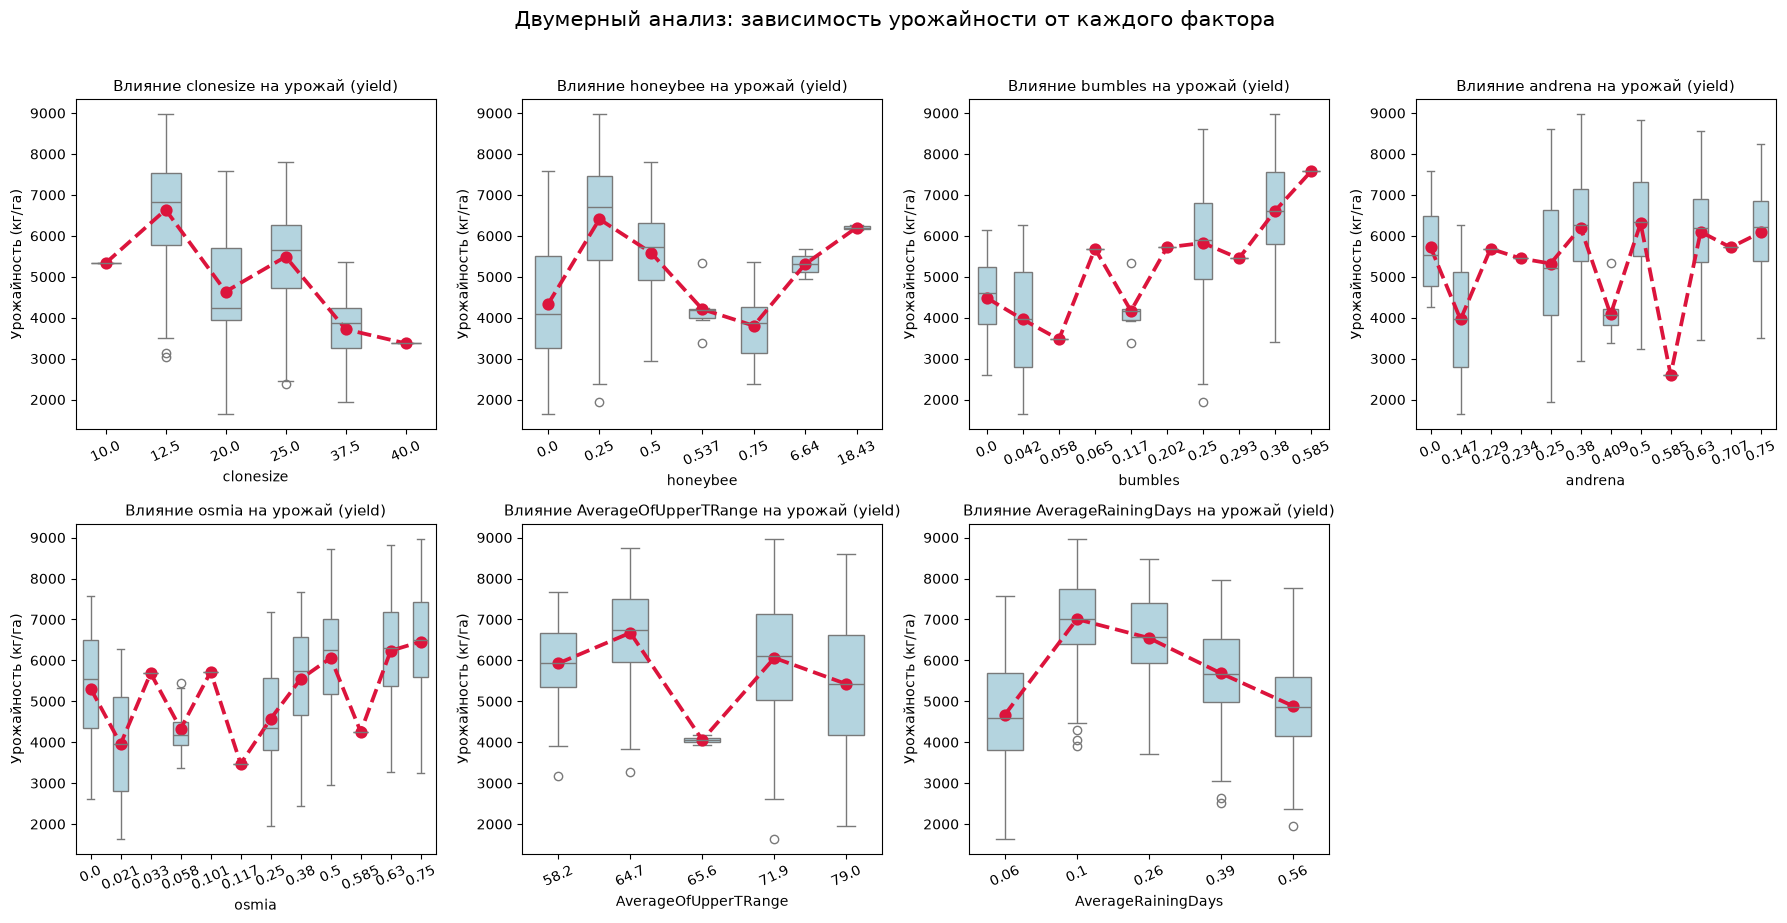

In [25]:
# Двумерный анализ: зависимость урожайности от каждого фактора
factors = [
    'clonesize',
    'honeybee',
    'bumbles',
    'andrena',
    'osmia',
    'AverageOfUpperTRange',
    'AverageRainingDays',
]

fig, axes = plt.subplots(2, 4, figsize=(18, 9))
axes = axes.flatten()

for i, col in enumerate(factors):
  # 1. Ящик с усами показывает разброс и медиану для каждого значения фактора
  sns.boxplot(
      data=df_base,
      x=col,
      y='yield',
      ax=axes[i],
      color='lightblue',
      width=0.5,
  )
  # 2. Pointplot поверх ящиков соединяет средние значения красной линией тренда
  sns.pointplot(
      data=df_base,
      x=col,
      y='yield',
      ax=axes[i],
      color='crimson',
      markers='o',
      linestyles='--',
      errorbar=None,
  )

  axes[i].set_title(f'Влияние {col} на урожай (yield)', fontsize=11)
  axes[i].set_xlabel(col)
  axes[i].set_ylabel('Урожайность (кг/га)')
  axes[i].tick_params(axis='x', rotation=25)

# Скрываем восьмую пустую ячейку
axes[-1].set_visible(False)

plt.suptitle(
    'Двумерный анализ: зависимость урожайности от каждого фактора',
    fontsize=15,
    y=1.02,
)
plt.tight_layout()
plt.show()


**Вывод**
- Размер куста (clonesize) — главный отрицательный фактор.
- Дикие пчёлы (osmia, bumbles, andrena) — нелинейный рост с «провалами» на редких уровнях.
- Погодные факторы (AverageOfUpperTRange и AverageRainingDays) — оптимальный диапазон (куполообразная кривая).
- Медоносные пчёлы (honeybee) — эффект насыщения и ложный пик.

## **6.2 «Что может способствовать повышению урожая?»**

In [28]:
# Определяем долю высоких урожаев
high_threshold = df_base['yield'].quantile(0.75)
df_base['is_high'] = (df_base['yield'] >= high_threshold).astype(int)

print(f"Порог высокого урожая: yield >= {high_threshold:.0f}")
print(df_base['is_high'].value_counts())
print(f"\nДоля высоких: {df_base['is_high'].mean() * 100:.1f}%")

Порог высокого урожая: yield >= 7022
is_high
0    582
1    195
Name: count, dtype: int64

Доля высоких: 25.1%


In [29]:
# Находим разницу в сравнении с высоким
high_comparison = df_base.groupby('is_high')[factors].median().T
high_comparison.columns = ['Обычные поля', 'Высокий урожай']
high_comparison['Разница'] = high_comparison['Высокий урожай'] - high_comparison['Обычные поля']
high_comparison['Разница %'] = ((high_comparison['Высокий урожай'] / high_comparison['Обычные поля'] - 1) * 100).round(1)
high_comparison.round(3)

,Обычные поля,Высокий урожай,Разница,Разница %
clonesize,25.00,12.50,-12.50,-50.0
honeybee,0.50,0.25,-0.25,-50.0
bumbles,0.25,0.25,0.00,0.0
andrena,0.50,0.50,0.00,0.0
osmia,0.50,0.63,0.13,26.0
AverageOfUpperTRange,71.90,64.70,-7.20,-10.0
AverageRainingDays,0.39,0.26,-0.13,-33.3


Факторы в разных единицах, поэтому их надо нормировать, и прривести к диапазон 0-1, берем средние вместо медиан, потому что некоторые параметры дискретные, а среднее чувствительно к изменению пропроций, что хорошо подходит для лепестковой диаграммы.

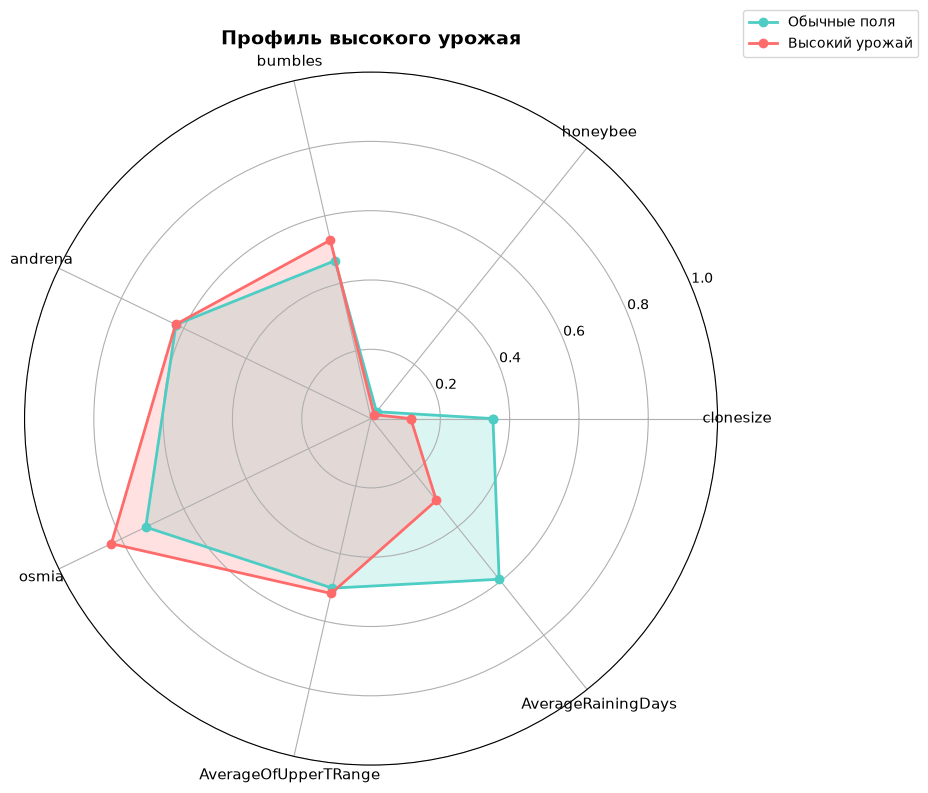

In [30]:
norm = df_base[factors].copy()
norm = (norm - norm.min()) / (norm.max() - norm.min())
norm['is_high'] = df_base['is_high']
profile_stats = norm.groupby('is_high')[factors].mean()

N = len(factors)
angles = [n / float(N) * 2 * pi for n in range(N)]
angles += angles[:1]

fig, ax = plt.subplots(figsize=(9, 9), subplot_kw=dict(polar=True))
for label, name, color in [(0, 'Обычные поля', '#4ECDC4'), (1, 'Высокий урожай', '#FF6B6B')]:
    values = profile_stats.loc[label].tolist()
    values += values[:1]
    ax.plot(angles, values, 'o-', linewidth=2, label=name, color=color)
    ax.fill(angles, values, alpha=0.2, color=color)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(factors, fontsize=11)
ax.set_ylim(0, 1)
ax.set_title('Профиль высокого урожая', fontsize=14, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
plt.show()

**Вывод**
- Ключевыми факторами высокой урожайности черники выступают более высокая численность osmia, bunmles, меньшее колличество дождливых дней и меньший размер клона.

In [31]:
# Пример для самого сильного положительного фактора (osmia) и отрицательного (RainingDays)
for col in ['bumbles', 'osmia', 'AverageRainingDays', 'clonesize']:
  summary = df_base.groupby(col)['yield'].agg(
      количество_строк='count',
      средний_урожай='mean',
      медиана='median',
      разброс_std='std',
  )
  print(f'\n--- Влияние фактора: {col} ---')
  print(summary.round(1))


--- Влияние фактора: bumbles ---
         количество_строк  средний_урожай  медиана  разброс_std
bumbles                                                        
0.000                   4          4482.0   4595.6       1471.8
0.042                   2          3957.1   3957.1       3280.1
0.058                   1          3471.2   3471.2          NaN
0.065                   1          5686.1   5686.1          NaN
0.117                   7          4167.1   4166.3        592.4
0.202                   1          5718.4   5718.4          NaN
0.250                 547          5827.8   5902.3       1312.7
0.293                   1          5449.4   5449.4          NaN
0.380                 212          6609.7   6601.0       1238.0
0.585                   1          7575.8   7575.8          NaN

--- Влияние фактора: osmia ---
       количество_строк  средний_урожай  медиана  разброс_std
osmia                                                        
0.000                 4          5312.3   

**Выводы**
- Размер клона, самый сильный фактор падения урожая.
- Кол-во дождя сильно влияет на урожай.
- Увеличение плотности шмелей положительно влияет на урожайность.
- Сильный эффект дает увеличение осмий, но до определенного кол-ва, далее наступает эффект насыщения и прирост уже слаыбый.

### Повторяющиеся сочетания пчёл и погоды

Группируем данные по плотности каждого вида пчёл, температуре и средней частоте дождливых дней. Сначала показываем повторяющиеся сценарии (`n >= 2`), чтобы не выдавать единичную запись за воспроизводимый максимум.

In [35]:
scenario_keys = [
    "honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays"
]

scenario_summary = (
    df.groupby(scenario_keys, dropna=False)["yield"]
      .agg(n="count", mean_yield="mean", median_yield="median",
           min_yield="min", max_yield="max", std_yield="std")
      .reset_index()
)

repeated_scenarios = scenario_summary[scenario_summary["n"] >= 2].copy()
print("Число уникальных сценариев:", len(scenario_summary))
print("Сценариев с двумя и более записями:", len(repeated_scenarios))

print("Повторяющиеся сценарии с наименьшей средней урожайностью:")
display(repeated_scenarios.nsmallest(10, "mean_yield"))
print("Повторяющиеся сценарии с наибольшей средней урожайностью:")
display(repeated_scenarios.nlargest(10, "mean_yield"))

Число уникальных сценариев: 735
Сценариев с двумя и более записями: 27
Повторяющиеся сценарии с наименьшей средней урожайностью:


,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,AverageRainingDays,n,mean_yield,median_yield,min_yield,max_yield,std_yield
23,0.250,0.250,0.250,0.250,79.0,0.56,3,2489.897359,2384.728916,1945.530615,3139.432546,603.859053
39,0.250,0.250,0.250,0.380,79.0,0.56,2,2974.516553,2974.516553,2452.680747,3496.352359,737.987274
22,0.250,0.250,0.250,0.250,79.0,0.39,3,3113.918447,3049.260316,2508.375673,3784.119353,640.324909
19,0.250,0.250,0.250,0.250,71.9,0.56,3,3214.806151,2988.059440,2688.028831,3968.330182,669.591996
11,0.250,0.250,0.250,0.250,58.2,0.56,2,3715.103787,3715.103787,3182.698648,4247.508926,752.934568
38,0.250,0.250,0.250,0.380,79.0,0.39,2,3781.081602,3781.081602,3385.148001,4177.015203,559.934668
35,0.250,0.250,0.250,0.380,71.9,0.56,2,3867.894447,3867.894447,3385.364224,4350.424670,682.400786
18,0.250,0.250,0.250,0.250,71.9,0.39,3,4016.374835,3662.183125,3387.785165,4999.156215,862.100917
15,0.250,0.250,0.250,0.250,64.7,0.56,3,4059.621111,3822.981667,3269.271761,5086.609905,931.492433
718,0.537,0.117,0.409,0.058,71.9,0.06,3,4311.090497,4225.961314,3373.436842,5333.873335,982.986798


Повторяющиеся сценарии с наибольшей средней урожайностью:


,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,AverageRainingDays,n,mean_yield,median_yield,min_yield,max_yield,std_yield
28,0.25,0.25,0.25,0.38,64.7,0.10,2,6944.596821,6944.596821,6318.708722,7570.484920,885.139438
32,0.25,0.25,0.25,0.38,71.9,0.10,2,6503.604187,6503.604187,5739.924933,7267.283440,1080.005558
29,0.25,0.25,0.25,0.38,64.7,0.26,2,6119.125631,6119.125631,5221.357411,7016.893850,1269.635992
36,0.25,0.25,0.25,0.38,79.0,0.10,2,5962.916105,5962.916105,5360.873908,6564.958302,851.416240
12,0.25,0.25,0.25,0.25,64.7,0.10,3,5901.348863,5831.706600,4830.959809,7041.380179,1106.854591
33,0.25,0.25,0.25,0.38,71.9,0.26,2,5724.430294,5724.430294,4870.625368,6578.235221,1207.462507
16,0.25,0.25,0.25,0.25,71.9,0.10,3,5528.876922,5126.993178,4768.594369,6691.043218,1022.294137
25,0.25,0.25,0.25,0.38,58.2,0.26,2,5451.845745,5451.845745,4705.626533,6198.064956,1055.313329
8,0.25,0.25,0.25,0.25,58.2,0.10,3,5180.756171,5246.521458,4051.551293,6244.195761,1097.800640
37,0.25,0.25,0.25,0.38,79.0,0.26,2,5146.781884,5146.781884,4546.786741,5746.777027,848.521269


### Погодная карта средней урожайности

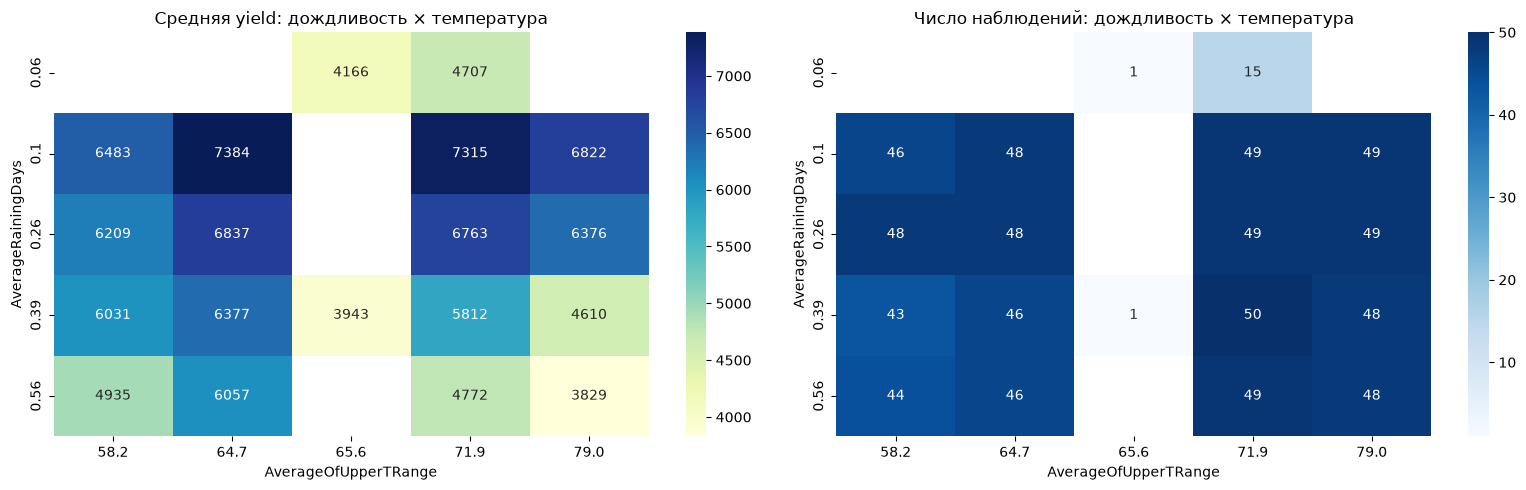

In [36]:
weather_mean = pd.pivot_table(
    df,
    index="AverageRainingDays",
    columns="AverageOfUpperTRange",
    values="yield",
    aggfunc="mean"
)
weather_count = pd.pivot_table(
    df,
    index="AverageRainingDays",
    columns="AverageOfUpperTRange",
    values="yield",
    aggfunc="count"
)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.heatmap(weather_mean, annot=True, fmt=".0f", cmap="YlGnBu", ax=axes[0])
axes[0].set_title("Средняя yield: дождливость × температура")
sns.heatmap(weather_count, annot=True, fmt=".0f", cmap="Blues", ax=axes[1])
axes[1].set_title("Число наблюдений: дождливость × температура")
plt.tight_layout()
plt.show()

## Анализ граничных значений факторов

Отмечаем наблюдения, в которых хотя бы один из ключевых внешних факторов находится на минимальном или максимальном уровне своего диапазона. Сравниваем их урожайность с остальными наблюдениями.

,n,yield_mean,yield_median,yield_min,yield_max
Группа,,,,,
Хотя бы один фактор на границе,588,5838.27,5866.69,1637.70,8969.40
Внутри диапазона,189,6555.99,6628.76,3387.79,8823.69


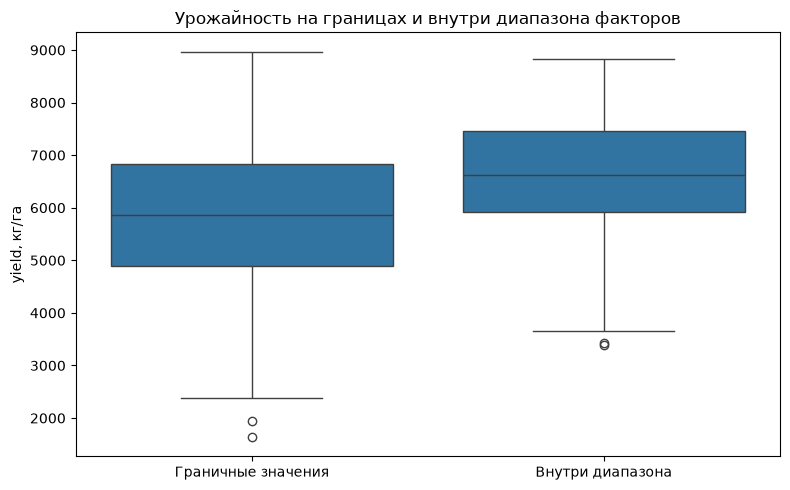

In [37]:
boundary_features = [
    "clonesize", "honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays"
]

boundary_mask = pd.Series(False, index=df.index)
for col in boundary_features:
    boundary_mask |= df[col].eq(df[col].min()) | df[col].eq(df[col].max())

df_boundary = df.loc[boundary_mask].copy()
df_interior = df.loc[~boundary_mask].copy()

boundary_comparison = pd.DataFrame({
    "Группа": ["Хотя бы один фактор на границе", "Внутри диапазона"],
    "n": [len(df_boundary), len(df_interior)],
    "yield_mean": [df_boundary["yield"].mean(), df_interior["yield"].mean()],
    "yield_median": [df_boundary["yield"].median(), df_interior["yield"].median()],
    "yield_min": [df_boundary["yield"].min(), df_interior["yield"].min()],
    "yield_max": [df_boundary["yield"].max(), df_interior["yield"].max()]
}).set_index("Группа")
display(boundary_comparison.round(2))

fig, ax = plt.subplots(figsize=(8, 5))
sns.boxplot(
    data=pd.concat([
        df_boundary.assign(boundary="Граничные значения"),
        df_interior.assign(boundary="Внутри диапазона")
    ]),
    x="boundary", y="yield", ax=ax
)
ax.set_title("Урожайность на границах и внутри диапазона факторов")
ax.set_xlabel("")
ax.set_ylabel("yield, кг/га")
plt.tight_layout()
plt.show()

# Часть 8. Feature Engineering — создание новых признаков

Ниже не просто список новых столбцов, а гипотезы, которые можно проверить. Все новые признаки строятся из входных факторов. Показатели `fruitset`, `fruitmass` и `seeds` рассматриваются отдельно как информация более позднего этапа: для раннего прогноза они могут создавать утечку будущей информации.

## 8.1. Общая и дикая плотность опылителей

- `pollinators_total` — сумма плотностей четырёх групп.
- `wild_bees_total` — сумма трёх групп диких пчёл, без медоносной.

Эти показатели проверяют гипотезу о том, важна ли общая интенсивность опыления или существеннее видовой состав.

In [38]:
df_ml = df.copy()

bee_cols = ["honeybee", "bumbles", "andrena", "osmia"]
wild_bee_cols = ["bumbles", "andrena", "osmia"]

df_ml["pollinators_total"] = df_ml[bee_cols].sum(axis=1)
df_ml["wild_bees_total"] = df_ml[wild_bee_cols].sum(axis=1)

# Доля каждого вида. Одну долю не включаем в линейную модель,
# поскольку сумма всех четырёх долей равна 1.
total_safe = df_ml["pollinators_total"].replace(0, np.nan)
for col in bee_cols:
    df_ml[f"{col}_share"] = (df_ml[col] / total_safe).fillna(0)

# Проверка суммы долей для ненулевой общей плотности.
share_cols = [f"{c}_share" for c in bee_cols]
display(df_ml[["pollinators_total", "wild_bees_total"] + share_cols].head())
print("Максимальное отклонение суммы долей от 1 при total > 0:")
nonzero_total = df_ml["pollinators_total"] > 0
print((df_ml.loc[nonzero_total, share_cols].sum(axis=1) - 1).abs().max())

,pollinators_total,wild_bees_total,honeybee_share,bumbles_share,andrena_share,osmia_share
Row#,,,,,,
0,1.5,0.75,0.5,0.166667,0.166667,0.166667
1,1.5,0.75,0.5,0.166667,0.166667,0.166667
2,1.5,0.75,0.5,0.166667,0.166667,0.166667
3,1.5,0.75,0.5,0.166667,0.166667,0.166667
4,1.5,0.75,0.5,0.166667,0.166667,0.166667


Максимальное отклонение суммы долей от 1 при total > 0:
2.220446049250313e-16


## 8.2 Богатство и разнообразие опылителей

Создаём три показателя:

- `bee_richness` — число видов/групп с ненулевой плотностью;
- `bee_shannon` — индекс разнообразия Шеннона: учитывает и число групп, и равномерность их долей;
- `bee_dominance_hhi` — сумма квадратов долей. Чем выше HHI, тем сильнее сообщество доминируется одной группой.

Это характеристики состава сообщества, а не прямые измерения качества опыления.

In [39]:
P = df_ml[bee_cols].div(df_ml["pollinators_total"].replace(0, np.nan), axis=0)
P = P.fillna(0)

# Число групп с ненулевой плотностью.
df_ml["bee_richness"] = (df_ml[bee_cols] > 0).sum(axis=1)

# Shannon: нулевые доли не участвуют в log(0).
P_log = P.where(P > 0, 1.0)
df_ml["bee_shannon"] = -(P * np.log(P_log)).sum(axis=1)

# Индекс концентрации / доминирования Херфиндаля.
df_ml["bee_dominance_hhi"] = (P ** 2).sum(axis=1)

# Если всех пчёл нет: разнообразие = 0, доминирование не определено;
# условно задаём HHI=0, а bee_richness=0 — отдельный индикатор отсутствия опылителей.
df_ml.loc[df_ml["pollinators_total"] == 0, "bee_dominance_hhi"] = 0

display(df_ml[["bee_richness", "bee_shannon", "bee_dominance_hhi"]].describe().round(3))

,bee_richness,bee_shannon,bee_dominance_hhi
count,777.000,777.000,777.000
mean,3.974,1.311,0.288
std,0.253,0.134,0.073
min,1.000,-0.000,0.250
25%,4.000,1.305,0.264
50%,4.000,1.332,0.278
75%,4.000,1.358,0.292
max,4.000,1.386,1.000


## 8.3 Преобразования асимметричных и потенциально нелинейных признаков

- `log1p_honeybee` — снижает влияние длинного правого хвоста honeybee и сохраняет нули.
- `log1p_pollinators_total` — альтернативная шкала общей активности.
- Квадратичные признаки для `clonesize`, `osmia` и дождливости позволяют проверить кривизну. Они не гарантируют улучшения качества и должны сравниваться на кросс-валидации.

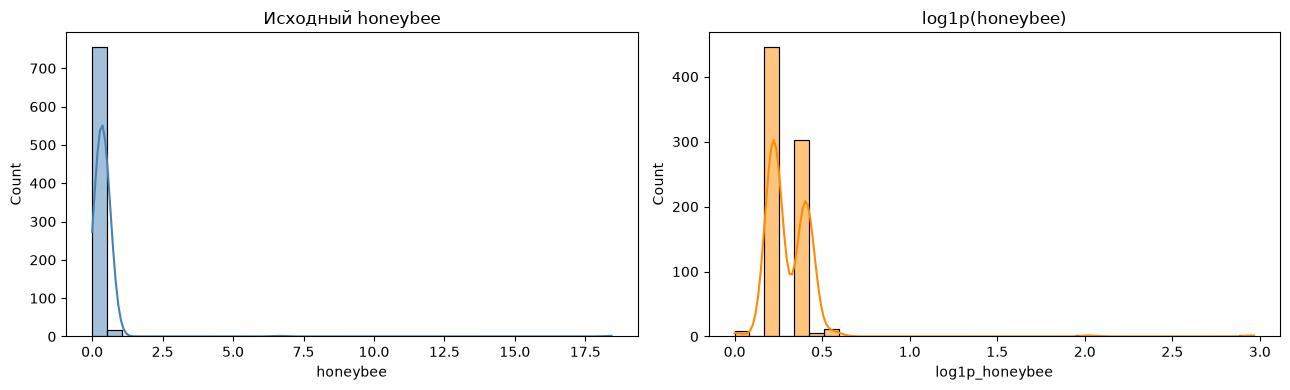

In [40]:
df_ml["log1p_honeybee"] = np.log1p(df_ml["honeybee"])
df_ml["log1p_pollinators_total"] = np.log1p(df_ml["pollinators_total"])

# Квадраты строим по центрированным признакам, чтобы уменьшить корреляцию x и x².
for col in ["clonesize", "osmia", "AverageRainingDays"]:
    centered = df_ml[col] - df_ml[col].mean()
    df_ml[f"{col}_centered_sq"] = centered ** 2

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df_ml["honeybee"], bins=35, kde=True, color="steelblue", ax=axes[0])
axes[0].set_title("Исходный honeybee")
sns.histplot(df_ml["log1p_honeybee"], bins=35, kde=True, color="darkorange", ax=axes[1])
axes[1].set_title("log1p(honeybee)")
plt.tight_layout()
plt.show()

## 8.4. Биологически осмысленные взаимодействия

Сформируем кандидаты:

- `honeybee × osmia` — меняется ли связь медоносной пчелы с урожаем в зависимости от осмий;
- `honeybee × bumbles` — аналогично для шмелей;
- `honeybee × дождливость` — меняется ли связь при более влажной погоде;
- `wild_bees_total × дождливость` — меняется ли связь диких пчёл с yield при росте дождливости.

Для лучшей интерпретации переменные центрируем перед умножением.

In [41]:
interaction_source_cols = [
    "honeybee", "osmia", "bumbles", "AverageRainingDays", "wild_bees_total"
]
centered_cols = {}
for col in interaction_source_cols:
    centered_cols[col] = df_ml[col] - df_ml[col].mean()

# Логарифм honeybee учитывает сильную асимметрию.
hb_centered = df_ml["log1p_honeybee"] - df_ml["log1p_honeybee"].mean()
osmia_centered = centered_cols["osmia"]
bumbles_centered = centered_cols["bumbles"]
rain_centered = centered_cols["AverageRainingDays"]
wild_centered = centered_cols["wild_bees_total"]

df_ml["log_honeybee_x_osmia"] = hb_centered * osmia_centered
df_ml["log_honeybee_x_bumbles"] = hb_centered * bumbles_centered
df_ml["log_honeybee_x_rain"] = hb_centered * rain_centered
df_ml["wild_bees_x_rain"] = wild_centered * rain_centered

display(df_ml[[
    "log_honeybee_x_osmia", "log_honeybee_x_bumbles",
    "log_honeybee_x_rain", "wild_bees_x_rain"
]].describe().round(3))

,log_honeybee_x_osmia,log_honeybee_x_bumbles,log_honeybee_x_rain,wild_bees_x_rain
count,777.000,777.000,777.000,777.000
mean,-0.004,-0.002,-0.002,0.005
std,0.091,0.043,0.045,0.055
min,-1.493,-0.750,-0.691,-0.135
25%,-0.006,-0.003,-0.021,-0.015
50%,0.005,0.003,0.005,0.003
75%,0.016,0.003,0.019,0.022
max,0.174,0.087,0.081,0.341


### Итог по Feature Engineering

Новые признаки имеют разные роли:

| Признак | Гипотеза | Риск / ограничение |
|---|---|---|
| `pollinators_total` | Важна общая плотность опылителей | Не включать вместе со всеми четырьмя исходными плотностями в одну линейную модель: сумма создаёт линейную зависимость |
| `wild_bees_total` | Важна суммарная активность диких пчёл | Пересекается с исходными тремя дикими группами |
| Доли видов | Важен состав сообщества, а не только сумма | В линейную модель включать не все четыре доли одновременно со свободным членом |
| `bee_richness`, `bee_shannon`, `bee_dominance_hhi` | Важны разнообразие и доминирование | Проверить, дают ли они пользу сверх плотностей отдельных видов |
| `log1p_honeybee` | Снижает влияние экстремально больших значений | Сравнить с исходным honeybee; не включать обе версии автоматически |
| Квадраты | Возможны нелинейность и эффект насыщения | Повышают риск переобучения и мультиколлинеарности |
| Взаимодействия | Эффект одного вида может зависеть от другого вида или погоды | Нужна проверка поддержки сочетаний и кросс-валидация |
---

# Часть 9. Подготовка вариантов датасета для регрессии

Создадим несколько **раздельных** наборов признаков. Каждый соответствует отдельному сценарию доступности информации.

In [42]:
# A — ранняя модель по внешним условиям и четырём группам опылителей.
features_A = [
    "clonesize", "honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays"
]

# B — та же информация, но асимметричный honeybee в логарифмической шкале.
features_B = [
    "clonesize", "log1p_honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays"
]

# C — состав сообщества: общая плотность + 3 доли; osmia_share — базовая доля.
features_C = [
    "clonesize", "pollinators_total",
    "honeybee_share", "bumbles_share", "andrena_share",
    "AverageOfUpperTRange", "AverageRainingDays"
]

# D — новые биологические агрегаты и разнообразие.
features_D = [
    "clonesize", "log1p_pollinators_total",
    "bee_richness", "bee_shannon", "bee_dominance_hhi",
    "AverageOfUpperTRange", "AverageRainingDays"
]

# E — взаимодействия и квадратичные термы, добавленные к базовым внешним факторам.
features_E = [
    "clonesize", "log1p_honeybee", "bumbles", "andrena", "osmia",
    "AverageOfUpperTRange", "AverageRainingDays",
    "clonesize_centered_sq", "osmia_centered_sq", "AverageRainingDays_centered_sq",
    "log_honeybee_x_osmia", "log_honeybee_x_bumbles",
    "log_honeybee_x_rain", "wild_bees_x_rain"
]

# F — промежуточный прогноз после формирования fruitset.
features_F = features_A + ["fruitset"]

# G — более поздняя оценка после появления массы ягод и семян.
features_G = features_F + ["fruitmass", "seeds"]

feature_sets = {
    "A_external_baseline": features_A,
    "B_log_honeybee": features_B,
    "C_pollinator_composition": features_C,
    "D_diversity_features": features_D,
    "E_interactions_nonlinearity": features_E,
    "F_after_fruitset": features_F,
    "G_late_stage": features_G
}

for name, cols in feature_sets.items():
    missing = sorted(set(cols) - set(df_ml.columns))
    if missing:
        raise ValueError(f"В наборе {name} отсутствуют признаки: {missing}")
    print(f"{name}: {len(cols)} признаков")

A_external_baseline: 7 признаков
B_log_honeybee: 7 признаков
C_pollinator_composition: 7 признаков
D_diversity_features: 7 признаков
E_interactions_nonlinearity: 14 признаков
F_after_fruitset: 8 признаков
G_late_stage: 10 признаков


## 9.1. Смысл разных вариантов

- **A–E** — прогноз по внешним характеристикам участка, опылителям и погоде периода цветения. Это сценарии разной сложности.
- **F** — прогноз после появления информации о завязываемости плодов.
- **G** — более поздняя оценка, когда уже известны дополнительные характеристики сформированных плодов.

`fruitset`, `fruitmass` и `seeds` нельзя использовать для прогноза до цветения: это информация о последующих этапах процесса. Их включение не является ошибкой само по себе, но меняет момент, на который делается прогноз.
## 9.2. Таблицы признаков и контроль пропусков

In [43]:
model_datasets = {}
for name, cols in feature_sets.items():
    model_datasets[name] = df_ml[cols + ["yield"]].copy()
    print(
        f"{name}: rows={len(model_datasets[name])}, "
        f"features={len(cols)}, "
        f"missing={model_datasets[name].isna().sum().sum()}"
    )

display(model_datasets["A_external_baseline"].head())

A_external_baseline: rows=777, features=7, missing=0
B_log_honeybee: rows=777, features=7, missing=0
C_pollinator_composition: rows=777, features=7, missing=0
D_diversity_features: rows=777, features=7, missing=0
E_interactions_nonlinearity: rows=777, features=14, missing=0
F_after_fruitset: rows=777, features=8, missing=0
G_late_stage: rows=777, features=10, missing=0


,clonesize,honeybee,bumbles,andrena,osmia,AverageOfUpperTRange,AverageRainingDays,yield
Row#,,,,,,,,
0,37.5,0.75,0.25,0.25,0.25,71.9,0.26,3813.165795
1,37.5,0.75,0.25,0.25,0.25,71.9,0.10,4947.605663
2,37.5,0.75,0.25,0.25,0.25,79.0,0.26,3866.798965
3,37.5,0.75,0.25,0.25,0.25,79.0,0.10,4303.943030
4,37.5,0.75,0.25,0.25,0.25,71.9,0.39,3436.493543
